<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 3: Classification

*Logistic regression, linear and quadratic discriminant analysis, naive Bayes, K-nearest neighbours, confusion matrices and ROC curves, and Poisson regression for counts*

**Chapter:** ISLP Chapter 4 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [1]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Mai Dong Huy"
STUDENT_ID   = "ITDSIU24019"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 3 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 3 | Mai Dong Huy | ITDSIU24019 | IT171IU – Lab Group 01


# <span style="color:red">1. Objectives</span>

<span style="color:red">After this lab you will be able to:</span>

- <span style="color:red">Fit and interpret a **logistic regression** model (`sm.GLM` with a binomial family, `LogisticRegression`).</span>
- <span style="color:red">Explain how **LDA, QDA and naive Bayes** use Bayes' theorem, and fit them with scikit-learn.</span>
- <span style="color:red">Use **K-nearest neighbours** and explain why predictors must be standardised first.</span>
- <span style="color:red">Evaluate classifiers with a **confusion matrix**: accuracy, error rate, sensitivity, specificity, precision; change the decision **threshold** and draw a **ROC curve**.</span>
- <span style="color:red">Use a training/test split (here by year) to estimate the **test** error honestly.</span>
- <span style="color:red">Fit a **Poisson regression** for count data and compare it with linear regression.</span>

> 📌 <span style="color:red">**Note** — **Lab plan – 150 minutes (3 periods)**</span>
>
> | <span style="color:red">Time</span> | <span style="color:red">Activity</span> |
> |---|---|
> | <span style="color:red">0 – 20 min</span> | <span style="color:red">Theory review: logistic regression, Bayes theorem, LDA/QDA/naive Bayes, KNN, evaluation metrics (Section 2)</span> |
> | <span style="color:red">20 – 80 min</span> | <span style="color:red">Guided lab: Smarket (logistic, LDA, QDA, NB, KNN), Caravan (KNN with scaling), Bikeshare (Poisson regression) (Section 3)</span> |
> | <span style="color:red">80 – 95 min</span> | <span style="color:red">Extra worked examples: thresholds, ROC curve and a classifier comparison on Default</span> |
> | <span style="color:red">95 – 140 min</span> | <span style="color:red">Exercises 1 – 6 (Section 4); challenge exercises 7 – 8 if time allows</span> |
> | <span style="color:red">140 – 150 min</span> | <span style="color:red">Run all cells, save and submit through the Google Form (Section 5)</span> |

# <span style="color:red">2. Theory</span>

## <span style="color:red">2.1 Why not linear regression?</span>

<span style="color:red">For a qualitative response (e.g. `Up`/`Down`, `Yes`/`No`) we want $\Pr(Y = k \mid X = x)$. A linear model can give "probabilities" below 0 or above 1 and imposes an arbitrary ordering when there are more than two classes. Classification methods model these probabilities directly.</span>

## <span style="color:red">2.2 Logistic regression</span>

<span style="color:red">For a binary response coded $Y\in\{0,1\}$, logistic regression models</span>

$$\color{red}{p(X) = \Pr(Y=1\mid X) = \frac{e^{\beta_0+\beta_1X_1+\dots+\beta_pX_p}}{1+e^{\beta_0+\beta_1X_1+\dots+\beta_pX_p}},}$$

<span style="color:red">which is equivalent to a linear model for the **log-odds (logit)**:</span>

$$\color{red}{\log\frac{p(X)}{1-p(X)} = \beta_0+\beta_1X_1+\dots+\beta_pX_p .}$$

<span style="color:red">A one-unit increase in $X_j$ multiplies the **odds** $p/(1-p)$ by $e^{\beta_j}$. The coefficients are estimated by **maximum likelihood**; `statsmodels` reports $z$-statistics and $p$-values just like the $t$-statistics in linear regression. We classify an observation as 1 when $\hat p(x) > 0.5$ (or another threshold).</span>

## <span style="color:red">2.3 Generative models: LDA, QDA and naive Bayes</span>

<span style="color:red">Instead of modelling $\Pr(Y\mid X)$ directly, we model the distribution $f_k(x)$ of $X$ in each class $k$ and the prior probabilities $\pi_k$, and use **Bayes' theorem**:</span>

$$\color{red}{\Pr(Y=k\mid X=x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)} .}$$

| <span style="color:red">Method</span> | <span style="color:red">Assumption on $f_k$</span> | <span style="color:red">Decision boundary</span> |
|---|---|---|
| <span style="color:red">**LDA**</span> | <span style="color:red">multivariate normal, class-specific mean $\mu_k$, **common** covariance $\Sigma$</span> | <span style="color:red">linear in $x$</span> |
| <span style="color:red">**QDA**</span> | <span style="color:red">multivariate normal with **class-specific** covariance $\Sigma_k$</span> | <span style="color:red">quadratic in $x$</span> |
| <span style="color:red">**Naive Bayes**</span> | <span style="color:red">predictors **independent** within each class ($f_k = f_{k1}\cdots f_{kp}$)</span> | <span style="color:red">flexible; works well when $p$ is large</span> |

<span style="color:red">LDA has few parameters (low variance) and is preferable when $n$ is small or the classes really share a covariance; QDA is more flexible (lower bias) and needs more data.</span>

## <span style="color:red">2.4 K-nearest neighbours (KNN)</span>

<span style="color:red">KNN makes no assumption about the shape of the decision boundary: it predicts the majority class among the $K$ training points closest to $x_0$. Because it uses distances, predictors measured on large scales dominate unless all variables are **standardised** (mean 0, standard deviation 1) – `StandardScaler()` in scikit-learn.</span>

## <span style="color:red">2.5 Evaluating a classifier</span>

|   | <span style="color:red">Predicted No (−)</span> | <span style="color:red">Predicted Yes (+)</span> |
|---|---|---|
| <span style="color:red">**True No (−)**</span> | <span style="color:red">True Negative (TN)</span> | <span style="color:red">False Positive (FP)</span> |
| <span style="color:red">**True Yes (+)**</span> | <span style="color:red">False Negative (FN)</span> | <span style="color:red">True Positive (TP)</span> |

- <span style="color:red">**Accuracy** $=(TP+TN)/n$; **error rate** $= 1 -$ accuracy.</span>
- <span style="color:red">**Sensitivity** (recall, true positive rate) $= TP/(TP+FN)$; **specificity** $= TN/(TN+FP)$; false positive rate $= 1-$ specificity.</span>
- <span style="color:red">**Precision** (positive predictive value) $= TP/(TP+FP)$.</span>

<span style="color:red">Lowering the threshold below 0.5 catches more positives (higher sensitivity) at the price of more false positives. The **ROC curve** plots the true positive rate against the false positive rate for all thresholds; the **AUC** (area under the curve) summarises it – 0.5 is random guessing, 1 is perfect. Note that ISLP's `confusion_table()` puts the **predictions in the rows** and the **truth in the columns**.</span>

## <span style="color:red">2.6 Poisson regression for counts</span>

<span style="color:red">When $Y$ is a count (0, 1, 2, …) such as the number of bike rentals, a linear model can predict negative values and assumes constant variance. **Poisson regression** assumes $Y\sim\text{Poisson}(\lambda(X))$ with</span>

$$\color{red}{\log \lambda(X) = \beta_0 + \beta_1X_1 + \dots + \beta_pX_p ,}$$

<span style="color:red">so a one-unit increase in $X_j$ multiplies the expected count by $e^{\beta_j}$, and the variance equals the mean. Logistic and Poisson regression are both **generalized linear models (GLMs)**: `sm.GLM(y, X, family=sm.families.Binomial())` or `family=sm.families.Poisson()`.</span>

# 3. Instructions and Worked Examples

<span style="color:red">Work through this section **in order**: read each explanation, *predict* what a cell will print, then run it. The black text and code are the original ISLP Chapter 4 lab; red notes, checkpoints and extra worked examples were added for IT171IU.</span>

### <span style="color:red">Setup cell</span>

In [2]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.13.14


In [3]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

## 3.1 The Stock Market Data

In this lab we will examine the `Smarket`
data, which is part of the `ISLP`
library. This data set consists of percentage returns for the S&P 500
stock index over 1,250 days, from the beginning of 2001 until the end
of 2005. For each date, we have recorded the percentage returns for
each of the five previous trading days,  `Lag1`  through
 `Lag5`. We have also recorded  `Volume`  (the number of
shares traded on the previous day, in billions),  `Today`  (the
percentage return on the date in question) and  `Direction`
(whether the market was  `Up`  or  `Down`  on this date).

We start by importing  our libraries at this top level; these are all imports we have seen in previous labs.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
                         summarize)

We also collect together the new imports needed for this lab.

In [5]:
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import \
     (LinearDiscriminantAnalysis as LDA,
      QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_curve, auc

Now we are ready to load the `Smarket` data.

In [6]:
Smarket = load_data('Smarket')
Smarket

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today,Direction
0,2001,0.381,-0.192,-2.624,-1.055,5.010,1.19130,0.959,Up
1,2001,0.959,0.381,-0.192,-2.624,-1.055,1.29650,1.032,Up
2,2001,1.032,0.959,0.381,-0.192,-2.624,1.41120,-0.623,Down
3,2001,-0.623,1.032,0.959,0.381,-0.192,1.27600,0.614,Up
4,2001,0.614,-0.623,1.032,0.959,0.381,1.20570,0.213,Up
...,...,...,...,...,...,...,...,...,...
1245,2005,0.422,0.252,-0.024,-0.584,-0.285,1.88850,0.043,Up
1246,2005,0.043,0.422,0.252,-0.024,-0.584,1.28581,-0.955,Down
1247,2005,-0.955,0.043,0.422,0.252,-0.024,1.54047,0.130,Up
1248,2005,0.130,-0.955,0.043,0.422,0.252,1.42236,-0.298,Down


This gives a truncated listing of the data.
We can see what the variable names are.

In [7]:
Smarket.columns

Index(['Year', 'Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today',
       'Direction'],
      dtype='object')

We compute the correlation matrix using the `corr()` method
for data frames, which produces a matrix that contains all of
the pairwise correlations among the variables.

By instructing `pandas` to use only numeric variables, the `corr()` method does not report a correlation for the `Direction`  variable because it is
 qualitative.

In [8]:
Smarket.corr(numeric_only=True)

,Year,Lag1,Lag2,Lag3,Lag4,Lag5,Volume,Today
Year,1.000000,0.029700,0.030596,0.033195,0.035689,0.029788,0.539006,0.030095
Lag1,0.029700,1.000000,-0.026294,-0.010803,-0.002986,-0.005675,0.040910,-0.026155
Lag2,0.030596,-0.026294,1.000000,-0.025897,-0.010854,-0.003558,-0.043383,-0.010250
Lag3,0.033195,-0.010803,-0.025897,1.000000,-0.024051,-0.018808,-0.041824,-0.002448
Lag4,0.035689,-0.002986,-0.010854,-0.024051,1.000000,-0.027084,-0.048414,-0.006900
Lag5,0.029788,-0.005675,-0.003558,-0.018808,-0.027084,1.000000,-0.022002,-0.034860
Volume,0.539006,0.040910,-0.043383,-0.041824,-0.048414,-0.022002,1.000000,0.014592
Today,0.030095,-0.026155,-0.010250,-0.002448,-0.006900,-0.034860,0.014592,1.000000


As one would expect, the correlations between the lagged return  variables and
today’s return are close to zero.  The only substantial correlation is between  `Year`  and
 `Volume`. By plotting the data we see that  `Volume`
is increasing over time. In other words, the average number of shares traded
daily increased from 2001 to 2005.

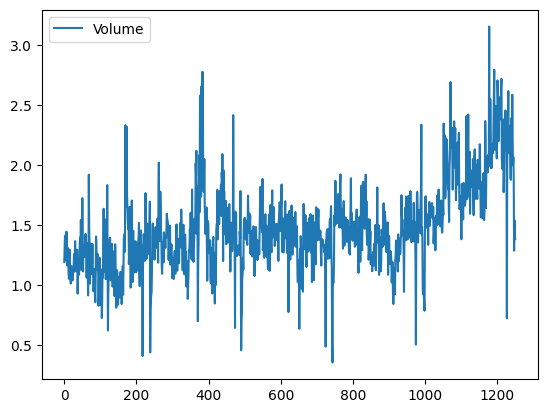

In [9]:
Smarket.plot(y='Volume');

## 3.2 Logistic Regression
Next, we will fit a logistic regression model in order to predict
 `Direction`  using  `Lag1`  through  `Lag5`  and
 `Volume`. The `sm.GLM()`  function fits *generalized linear models*, a class of
models that includes logistic regression.  Alternatively,
the function `sm.Logit()` fits a logistic regression
model directly. The syntax of
`sm.GLM()` is similar to that of `sm.OLS()`, except
that we must pass in the argument `family=sm.families.Binomial()`
in order to tell `statsmodels` to run a logistic regression rather than some other
type of generalized linear model.

In [10]:
allvars = Smarket.columns.drop(['Today', 'Direction', 'Year'])
design = MS(allvars)
X = design.fit_transform(Smarket)
y = Smarket.Direction == 'Up'
glm = sm.GLM(y,
             X,
             family=sm.families.Binomial())
results = glm.fit()
summarize(results)

,coef,std err,z,P>|z|
intercept,-0.1260,0.241,-0.523,0.601
Lag1,-0.0731,0.050,-1.457,0.145
Lag2,-0.0423,0.050,-0.845,0.398
Lag3,0.0111,0.050,0.222,0.824
Lag4,0.0094,0.050,0.187,0.851
Lag5,0.0103,0.050,0.208,0.835
Volume,0.1354,0.158,0.855,0.392


The smallest *p*-value here is associated with  `Lag1`. The
negative coefficient for this predictor suggests that if the market
had a positive return yesterday, then it is less likely to go up
today. However, at a value of 0.15, the *p*-value is still
relatively large, and so there is no clear evidence of a real
association between  `Lag1`  and  `Direction`.

We use the `params`  attribute of `results`
in order to access just the
coefficients for this fitted model.

In [11]:
results.params

intercept   -0.126000
Lag1        -0.073074
Lag2        -0.042301
Lag3         0.011085
Lag4         0.009359
Lag5         0.010313
Volume       0.135441
dtype: float64

Likewise we can use the
`pvalues`  attribute to access the *p*-values for the coefficients.

In [12]:
results.pvalues

intercept    0.600700
Lag1         0.145232
Lag2         0.398352
Lag3         0.824334
Lag4         0.851445
Lag5         0.834998
Volume       0.392404
dtype: float64

The `predict()`  method of `results` can be used to predict the
probability that the market will go up, given values of the
predictors. This method returns predictions
on the probability scale. If no data set is supplied to the `predict()`
function, then the probabilities are computed for the training data
that was used to fit the logistic regression model.
As with linear regression, one can pass an optional `exog` argument consistent
with a design matrix if desired. Here we have
printed only the first ten probabilities.

In [13]:
probs = results.predict()
probs[:10]

array([0.50708413, 0.48146788, 0.48113883, 0.51522236, 0.51078116,
       0.50695646, 0.49265087, 0.50922916, 0.51761353, 0.48883778])

In order to make a prediction as to whether the market will go up or
down on a particular day, we must convert these predicted
probabilities into class labels,  `Up`  or  `Down`.  The
following two commands create a vector of class predictions based on
whether the predicted probability of a market increase is greater than
or less than 0.5.

In [14]:
labels = np.array(['Down']*1250)
labels[probs>0.5] = "Up"

The `confusion_table()`
function from the `ISLP` package summarizes these predictions, showing   how
many observations were correctly or incorrectly classified. Our function, which is adapted from a similar function
in the module `sklearn.metrics`,  transposes the resulting
matrix and includes row and column labels.
The `confusion_table()` function takes as first argument the
predicted labels, and second argument the true labels.

In [15]:
confusion_table(labels, Smarket.Direction)

Truth,Down,Up
Predicted,,
Down,145,141
Up,457,507


The diagonal elements of the confusion matrix indicate correct
predictions, while the off-diagonals represent incorrect
predictions. Hence our model correctly predicted that the market would
go up on 507 days and that it would go down on 145 days, for a
total of 507 + 145 = 652 correct predictions. The `np.mean()`
function can be used to compute the fraction of days for which the
prediction was correct. In this case, logistic regression correctly
predicted the movement of the market 52.2% of the time.

In [16]:
(507+145)/1250, np.mean(labels == Smarket.Direction)

(0.5216, np.float64(0.5216))

At first glance, it appears that the logistic regression model is
working a little better than random guessing. However, this result is
misleading because we trained and tested the model on the same set of
1,250 observations. In other words, $100-52.2=47.8%$ is the
*training* error  rate. As we have seen
previously, the training error rate is often overly optimistic --- it
tends to underestimate the test error rate.  In
order to better assess the accuracy of the logistic regression model
in this setting, we can fit the model using part of the data, and
then examine how well it predicts the *held out* data.  This
will yield a more realistic error rate, in the sense that in practice
we will be interested in our model’s performance not on the data that
we used to fit the model, but rather on days in the future for which
the market’s movements are unknown.

To implement this strategy, we first create a Boolean vector
corresponding to the observations from 2001 through 2004. We  then
use this vector to create a held out data set of observations from
2005.

In [17]:
train = (Smarket.Year < 2005)
Smarket_train = Smarket.loc[train]
Smarket_test = Smarket.loc[~train]
Smarket_test.shape

(252, 9)

The object `train` is a vector of 1,250 elements, corresponding
to the observations in our data set. The elements of the vector that
correspond to observations that occurred before 2005 are set to
`True`, whereas those that correspond to observations in 2005 are
set to `False`.  Hence `train` is a
*boolean*   array, since its
elements are `True` and `False`.  Boolean arrays can be used
to obtain a subset of the rows or columns of a data frame
using the `loc` method. For instance,
the command `Smarket.loc[train]` would pick out a submatrix of the
stock market data set, corresponding only to the dates before 2005,
since those are the ones for which the elements of `train` are
`True`.  The `~` symbol can be used to negate all of the
elements of a Boolean vector. That is, `~train` is a vector
similar to `train`, except that the elements that are `True`
in `train` get swapped to `False` in `~train`, and vice versa.
Therefore, `Smarket.loc[~train]` yields a
subset of the rows of the data frame
of the stock market data containing only the observations for which
`train` is `False`.
The output above indicates that there are 252 such
observations.

We now fit a logistic regression model using only the subset of the
observations that correspond to dates before 2005. We then obtain predicted probabilities of the
stock market going up for each of the days in our test set --- that is,
for the days in 2005.

In [18]:
X_train, X_test = X.loc[train], X.loc[~train]
y_train, y_test = y.loc[train], y.loc[~train]
glm_train = sm.GLM(y_train,
                   X_train,
                   family=sm.families.Binomial())
results = glm_train.fit()
probs = results.predict(exog=X_test)

Notice that we have trained and tested our model on two completely
separate data sets: training was performed using only the dates before
2005, and testing was performed using only the dates in 2005.

Finally, we compare the predictions for 2005 to the
actual movements of the market over that time period.
We will first store the test and training labels (recall `y_test` is binary).

In [19]:
D = Smarket.Direction
L_train, L_test = D.loc[train], D.loc[~train]

Now we threshold the
fitted probability at 50% to form
our predicted labels.

In [20]:
labels = np.array(['Down']*252)
labels[probs>0.5] = 'Up'
confusion_table(labels, L_test)

Truth,Down,Up
Predicted,,
Down,77,97
Up,34,44


The test accuracy is about 48% while the error rate is about 52%

In [21]:
np.mean(labels == L_test), np.mean(labels != L_test)

(np.float64(0.4801587301587302), np.float64(0.5198412698412699))

The `!=` notation means *not equal to*, and so the last command
computes the test set error rate. The results are rather
disappointing: the test error rate is 52%, which is worse than
random guessing! Of course this result is not all that surprising,
given that one would not generally expect to be able to use previous
days’ returns to predict future market performance. (After all, if it
were possible to do so, then the authors of this book would be out
striking it rich rather than writing a statistics textbook.)

We recall that the logistic regression model had very underwhelming
*p*-values associated with all of the predictors, and that the
smallest *p*-value, though not very small, corresponded to
 `Lag1`. Perhaps by removing the variables that appear not to be
helpful in predicting  `Direction`, we can obtain a more
effective model. After all, using predictors that have no relationship
with the response tends to cause a deterioration in the test error
rate (since such predictors cause an increase in variance without a
corresponding decrease in bias), and so removing such predictors may
in turn yield an improvement.  Below we refit the logistic
regression using just  `Lag1`  and  `Lag2`, which seemed to
have the highest predictive power in the original logistic regression
model.

In [22]:
model = MS(['Lag1', 'Lag2']).fit(Smarket)
X = model.transform(Smarket)
X_train, X_test = X.loc[train], X.loc[~train]
glm_train = sm.GLM(y_train,
                   X_train,
                   family=sm.families.Binomial())
results = glm_train.fit()
probs = results.predict(exog=X_test)
labels = np.array(['Down']*252)
labels[probs>0.5] = 'Up'
confusion_table(labels, L_test)

Truth,Down,Up
Predicted,,
Down,35,35
Up,76,106


Let’s evaluate the overall accuracy as well as the accuracy within the days when
logistic regression predicts an increase.

In [23]:
(35+106)/252,106/(106+76)

(0.5595238095238095, 0.5824175824175825)

Now the results appear to be a little better: 56% of the daily
movements have been correctly predicted. It is worth noting that in
this case, a much simpler strategy of predicting that the market will
increase every day will also be correct 56% of the time! Hence, in
terms of overall error rate, the logistic regression method is no
better than the naive approach. However, the confusion matrix
shows that on days when logistic regression predicts an increase in
the market, it has a 58% accuracy rate. This suggests a possible
trading strategy of buying on days when the model predicts an
increasing market, and avoiding trades on days when a decrease is
predicted. Of course one would need to investigate more carefully
whether this small improvement was real or just due to random chance.

Suppose that we want to predict the returns associated with particular
values of  `Lag1`  and  `Lag2`. In particular, we want to
predict  `Direction`  on a day when  `Lag1`  and
 `Lag2`  equal $1.2$ and $1.1$, respectively, and on a day when they
equal $1.5$ and $-0.8$.  We do this using the `predict()`
function.

In [24]:
newdata = pd.DataFrame({'Lag1':[1.2, 1.5],
                        'Lag2':[1.1, -0.8]});
newX = model.transform(newdata)
results.predict(newX)

0    0.479146
1    0.496094
dtype: float64

> ✅ <span style="color:red">**Checkpoint** — **Logistic regression**</span>
>
> 1. <span style="color:red">On the training data the full model has accuracy 52.2%, yet the training error is an optimistic estimate. Why?</span>
> 2. <span style="color:red">What test accuracy does the model with only `Lag1` and `Lag2` achieve? What would a naive rule "always predict Up" achieve on the 2005 data?</span>
> 3. <span style="color:red">Interpret the sign of the coefficient of `Lag1` in terms of odds.</span>

## 3.3 Linear Discriminant Analysis

We begin by performing LDA on the  `Smarket`  data, using the function
`LinearDiscriminantAnalysis()`, which we have abbreviated `LDA()`. We
fit the model using only the observations before 2005.

In [25]:
lda = LDA(store_covariance=True)

Since the `LDA` estimator automatically
adds an intercept, we should remove the column corresponding to the
intercept in both `X_train` and `X_test`. We can also directly
use the labels rather than the Boolean vectors `y_train`.

In [26]:
X_train, X_test = [M.drop(columns=['intercept'])
                   for M in [X_train, X_test]]
lda.fit(X_train, L_train)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",True
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


Here we have used the list comprehensions introduced
in Section 3.6.4. Looking at our first line above, we see that the right-hand side is a list
of length two. This is because the code `for M in [X_train, X_test]` iterates over a list
of length two. While here we loop over a list,
the list comprehension method works when looping over any iterable object.
We then apply the `drop()` method to each element in the iteration, collecting
the result in a list. The left-hand side tells `Python` to unpack this list
of length two, assigning its elements to the variables `X_train` and `X_test`. Of course,
this overwrites the previous values of `X_train` and `X_test`.

Having fit the model, we can extract the means in the two classes with the `means_` attribute. These are the average of each predictor within each class, and
are used by LDA as estimates of $\mu_k$.  These suggest that there is
a tendency for the previous 2 days’ returns to be negative on days
when the market increases, and a tendency for the previous days’
returns to be positive on days when the market declines.

In [27]:
lda.means_

array([[ 0.04279022,  0.03389409],
       [-0.03954635, -0.03132544]])

The estimated prior probabilities are stored in the `priors_` attribute.
The package `sklearn` typically uses this trailing `_` to denote
a quantity estimated when using the `fit()` method. We can be sure of which
entry corresponds to which label by looking at the `classes_` attribute.

In [28]:
lda.classes_

array(['Down', 'Up'], dtype='<U4')

The LDA output indicates that $\hat\pi_{Down}=0.492$ and
$\hat\pi_{Up}=0.508$.

In [29]:
lda.priors_

array([0.49198397, 0.50801603])

The linear discriminant vectors can be found in the `scalings_` attribute:

In [30]:
lda.scalings_

array([[-0.64201904],
       [-0.51352928]])

These values provide the linear combination of `Lag1`  and `Lag2`  that are used to form the LDA decision rule. In other words, these are the multipliers of the elements of $X=x$ in (4.24).
  If $-0.64\times `Lag1`  - 0.51 \times `Lag2` $ is large, then the LDA classifier will predict a market increase, and if it is small, then the LDA classifier will predict a market decline.

In [31]:
lda_pred = lda.predict(X_test)

As we observed in our comparison of classification methods
 (Section 4.5),  the LDA and logistic
regression predictions are almost identical.

In [32]:
confusion_table(lda_pred, L_test)

Truth,Down,Up
Predicted,,
Down,35,35
Up,76,106


We can also estimate the
probability of each class for
each point in a training set. Applying a 50% threshold to the posterior probabilities of
being in class one allows us to
recreate the predictions contained in `lda_pred`.

In [33]:
lda_prob = lda.predict_proba(X_test)
np.all(
       np.where(lda_prob[:,1] >= 0.5, 'Up','Down') == lda_pred
       )

np.True_

Above, we used the `np.where()`  function that
creates an array with value `'Up'` for indices where
the second column of `lda_prob` (the estimated
posterior probability of `'Up'`) is greater than 0.5.
For problems with more than two classes the labels are chosen as the class whose posterior probability is highest:

In [34]:
np.all(
       [lda.classes_[i] for i in np.argmax(lda_prob, 1)] == lda_pred
       )

np.True_

If we wanted to use a posterior probability threshold other than
50% in order to make predictions, then we could easily do so. For
instance, suppose that we wish to predict a market decrease only if we
are very certain that the market will indeed decrease on that
day --- say, if the posterior probability is at least 90%.
We know that the first column of `lda_prob` corresponds to the
label `Down` after having checked the `classes_` attribute, hence we use
the column index 0 rather than 1 as we did above.

In [35]:
np.sum(lda_prob[:,0] > 0.9)

np.int64(0)

No days in 2005 meet that threshold! In fact, the greatest posterior
probability of decrease in all of 2005 was 52.02%.

The LDA classifier above is the first classifier from the
`sklearn` library. We will use several other objects
from this library. The objects
follow a common structure that simplifies tasks such as cross-validation,
which we will see in Chapter 5. Specifically,
the methods first create a generic classifier without
referring to any data. This classifier is then fit
to data with the `fit()`  method and predictions are
always produced with the `predict()` method. This pattern
of first instantiating the classifier, followed by fitting it, and
then producing predictions is an explicit design choice of `sklearn`. This uniformity
makes it possible to cleanly copy the classifier so that it can be fit
on different data; e.g. different training sets arising in cross-validation.
This standard pattern also allows for a predictable formation of workflows.

## 3.4 Quadratic Discriminant Analysis
We will now fit a QDA model to the  `Smarket`  data. QDA is
implemented via
`QuadraticDiscriminantAnalysis()`
in the `sklearn` package, which we abbreviate to `QDA()`.
The syntax is very similar to `LDA()`.

In [36]:
qda = QDA(store_covariance=True)
qda.fit(X_train, L_train)

,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",True
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None


The `QDA()` function will again compute `means_` and `priors_`.

In [37]:
qda.means_, qda.priors_

(array([[ 0.04279022,  0.03389409],
        [-0.03954635, -0.03132544]]),
 array([0.49198397, 0.50801603]))

The `QDA()` classifier will estimate one covariance per class. Here is the
estimated covariance in the first class:

In [38]:
qda.covariance_[0]

array([[ 1.50662277, -0.03924806],
       [-0.03924806,  1.53559498]])

The output contains the group means. But it does not contain the
coefficients of the linear discriminants, because the QDA classifier
involves a quadratic, rather than a linear, function of the
predictors. The `predict()`  function works in exactly the
same fashion as for LDA.

In [39]:
qda_pred = qda.predict(X_test)
confusion_table(qda_pred, L_test)

Truth,Down,Up
Predicted,,
Down,30,20
Up,81,121


Interestingly, the QDA predictions are accurate almost 60% of the
time, even though the 2005 data was not used to fit the model.

In [40]:
np.mean(qda_pred == L_test)

np.float64(0.5992063492063492)

This level of accuracy is quite impressive for stock market data, which is
known to be quite hard to model accurately.  This suggests that the
quadratic form assumed by QDA may capture the true relationship more
accurately than the linear forms assumed by LDA and logistic
regression.  However, we recommend evaluating this method’s
performance on a larger test set before betting that this approach
will consistently beat the market!

## 3.5 Naive Bayes
Next, we fit a naive Bayes model to the `Smarket` data. The syntax is
similar to that of `LDA()` and `QDA()`. By
default, this implementation `GaussianNB()` of the naive Bayes classifier models each
quantitative feature using a Gaussian distribution. However, a kernel
density method can also be used to estimate the distributions.

In [41]:
NB = GaussianNB()
NB.fit(X_train, L_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09


The classes are stored as `classes_`.

In [42]:
NB.classes_

array(['Down', 'Up'], dtype='<U4')

The class prior probabilities are stored in the `class_prior_` attribute.

In [43]:
NB.class_prior_

array([0.49198397, 0.50801603])

The parameters of the features can be found in the `theta_` and `var_` attributes. The number of rows
is equal to the number of classes, while the number of columns is equal to the number of features.
We see below that the mean for feature `Lag1` in the `Down` class is 0.043.

In [44]:
NB.theta_

array([[ 0.04279022,  0.03389409],
       [-0.03954635, -0.03132544]])

Its variance is 1.503.

In [45]:
NB.var_

array([[1.50355429, 1.53246749],
       [1.51401364, 1.48732877]])

How do we know the names of these attributes? We use `NB?` (or `?NB`).

We can easily verify the mean computation:

In [46]:
X_train[L_train == 'Down'].mean()

Lag1    0.042790
Lag2    0.033894
dtype: float64

Similarly for the variance:

In [47]:
X_train[L_train == 'Down'].var(ddof=0)

Lag1    1.503554
Lag2    1.532467
dtype: float64

Since `NB()` is a classifier in the `sklearn` library, making predictions
uses the same syntax as for `LDA()` and `QDA()` above.

In [48]:
nb_labels = NB.predict(X_test)
confusion_table(nb_labels, L_test)

Truth,Down,Up
Predicted,,
Down,29,20
Up,82,121


Naive Bayes performs well on these data, with accurate predictions over 59% of the time. This is slightly worse than QDA, but much better than LDA.

As for `LDA`, the `predict_proba()` method estimates the probability that each observation belongs to a particular class.

In [49]:
NB.predict_proba(X_test)[:5]

array([[0.4873288 , 0.5126712 ],
       [0.47623584, 0.52376416],
       [0.46529531, 0.53470469],
       [0.47484469, 0.52515531],
       [0.49020587, 0.50979413]])

> ✅ <span style="color:red">**Checkpoint** — **Generative models**</span>
>
> 1. <span style="color:red">Look at `lda.priors_` and `lda.means_`: what do they estimate?</span>
> 2. <span style="color:red">QDA has a higher test accuracy than LDA here. What does this suggest about the true decision boundary?</span>
> 3. <span style="color:red">Verify one entry of `NB.theta_` with a pandas `groupby().mean()` command.</span>

## 3.6 K-Nearest Neighbors
We will now perform KNN using the `KNeighborsClassifier()` function. This function works similarly
to the other model-fitting functions that we have
encountered thus far.

As is the
case for LDA and QDA, we fit the classifier
using the `fit` method. New
predictions are formed using the `predict` method
of the object returned by `fit()`.

In [50]:
knn1 = KNeighborsClassifier(n_neighbors=1)
X_train, X_test = [np.asarray(X) for X in [X_train, X_test]]
knn1.fit(X_train, L_train)
knn1_pred = knn1.predict(X_test)
confusion_table(knn1_pred, L_test)

Truth,Down,Up
Predicted,,
Down,43,58
Up,68,83


The results using $K=1$ are not very good, since only $50%$ of the
observations are correctly predicted. Of course, it may be that $K=1$
results in an overly-flexible fit to the data.

In [51]:
(83+43)/252, np.mean(knn1_pred == L_test)

(0.5, np.float64(0.5))

We repeat the
analysis below using $K=3$.

In [52]:
knn3 = KNeighborsClassifier(n_neighbors=3)
knn3_pred = knn3.fit(X_train, L_train).predict(X_test)
np.mean(knn3_pred == L_test)

np.float64(0.5317460317460317)

The results have improved slightly. But increasing *K* further
provides no further improvements. It appears that for these data, and this train/test split,
QDA gives the best results of the methods that we have examined so
far.

KNN does not perform well on the `Smarket`  data, but it often does provide impressive results. As an example we will apply the KNN approach to the `Caravan`  data set, which is part of the `ISLP` library.  This data set includes 85
predictors that measure demographic characteristics for 5,822
individuals. The response variable is  `Purchase`, which
indicates whether or not a given individual purchases a caravan
insurance policy. In this data set, only 6% of people purchased
caravan insurance.

In [53]:
Caravan = load_data('Caravan')
Purchase = Caravan.Purchase
Purchase.value_counts()

Purchase
No     5474
Yes     348
Name: count, dtype: int64

The method `value_counts()` takes a `pd.Series` or `pd.DataFrame` and returns
a `pd.Series` with the corresponding counts
for each unique element. In this case `Purchase` has only `Yes` and `No` values
and the method returns how many values of each there are.

In [54]:
348 / 5822

0.05977327378907592

Our features will include all columns except `Purchase`.

In [55]:
feature_df = Caravan.drop(columns=['Purchase'])

Because the KNN classifier predicts the class of a given test
observation by identifying the observations that are nearest to it,
the scale of the variables matters. Any variables that are on a large
scale will have a much larger effect on the *distance* between
the observations, and hence on the KNN classifier, than variables that
are on a small scale. For instance, imagine a data set that contains
two variables,  `salary`  and  `age`  (measured in dollars
and years, respectively). As far as KNN is concerned, a difference of
1,000 USD in salary is enormous compared to a difference of 50 years in
age. Consequently,  `salary`  will drive the KNN classification
results, and  `age`  will have almost no effect. This is contrary
to our intuition that a salary difference of 1,000 USD is quite small
compared to an age difference of 50 years.  Furthermore, the
importance of scale to the KNN classifier leads to another issue: if
we measured  `salary`  in Japanese yen, or if we measured
 `age`  in minutes, then we’d get quite different classification
results from what we get if these two variables are measured in
dollars and years.

A good way to handle this problem is to *standardize*  the data so that all variables are
given a mean of zero and a standard deviation of one. Then all
variables will be on a comparable scale. This is accomplished
using
the `StandardScaler()`
transformation.

In [56]:
scaler = StandardScaler(with_mean=True,
                        with_std=True,
                        copy=True)

The argument `with_mean` indicates whether or not
we should subtract the mean, while `with_std` indicates
whether or not we should scale the columns to have standard
deviation of 1 or not. Finally, the argument `copy=True`
indicates that we will always copy data, rather than
trying to do calculations in place where possible.

This transformation can be fit
and then applied to arbitrary data. In the first line
below, the parameters for the scaling are computed and
stored in `scaler`, while the second line actually
constructs the standardized set of features.

In [57]:
scaler.fit(feature_df)
X_std = scaler.transform(feature_df)

Now every column of `feature_std` below has a standard deviation of
one and a mean of zero.

In [58]:
feature_std = pd.DataFrame(
                 X_std,
                 columns=feature_df.columns);
feature_std.std()

MOSTYPE     1.000086
MAANTHUI    1.000086
MGEMOMV     1.000086
MGEMLEEF    1.000086
MOSHOOFD    1.000086
              ...   
AZEILPL     1.000086
APLEZIER    1.000086
AFIETS      1.000086
AINBOED     1.000086
ABYSTAND    1.000086
Length: 85, dtype: float64

Notice that the standard deviations are not quite $1$ here; this is again due to some procedures using the $1/n$ convention for variances (in this case `scaler()`), while others use $1/(n-1)$ (the `std()` method). See the footnote on page 183.
In this case it does not matter, as long as the variables are all on the same scale.

Using the function `train_test_split()`  we now split the observations into a test set,
containing 1000 observations, and a training set containing the remaining
observations. The argument `random_state=0` ensures that we get
the same split each time we rerun the code.

In [59]:
(X_train,
 X_test,
 y_train,
 y_test) = train_test_split(np.asarray(feature_std),
                            Purchase,
                            test_size=1000,
                            random_state=0)

`?train_test_split` reveals that the non-keyword arguments can be `lists`, `arrays`, `pandas dataframes` etc that all have the same length (`shape[0]`) and hence are *indexable*. In this case they are the dataframe `feature_std` and the response variable `Purchase`.
 {Note that we have converted `feature_std` to an `ndarray` to address a bug in `sklearn`.}
We fit a KNN model on the training data using $K=1$,
and evaluate its performance on the test data.

In [60]:
knn1 = KNeighborsClassifier(n_neighbors=1)
knn1_pred = knn1.fit(X_train, y_train).predict(X_test)
np.mean(y_test != knn1_pred), np.mean(y_test != "No")

(np.float64(0.111), np.float64(0.067))

The KNN error rate on the 1,000 test observations is about $11%$.
At first glance, this may appear to be fairly good. However, since
just over 6% of customers purchased insurance, we could get the error
rate down to almost 6% by always predicting `No` regardless of the
values of the predictors! This is known as the *null rate*.}

Suppose that there is some non-trivial cost to trying to sell
insurance to a given individual. For instance, perhaps a salesperson
must visit each potential customer.  If the company tries to sell
insurance to a random selection of customers, then the success rate
will be only 6%, which may be far too low given the costs
involved.  Instead, the company would like to try to sell insurance
only to customers who are likely to buy it. So the overall error rate
is not of interest. Instead, the fraction of individuals that are
correctly predicted to buy insurance is of interest.

In [61]:
confusion_table(knn1_pred, y_test)

Truth,No,Yes
Predicted,,
No,880,58
Yes,53,9


It turns out that KNN with $K=1$ does far better than random guessing
among the customers that are predicted to buy insurance. Among 62
such customers, 9, or 14.5%, actually do purchase insurance.
This is double the rate that one would obtain from random guessing.

In [62]:
9/(53+9)

0.14516129032258066

### Tuning Parameters

The number of neighbors in KNN is referred to as a *tuning parameter*, also referred to as a *hyperparameter*.
We do not know *a priori* what value to use. It is therefore of interest
to see how the classifier performs on test data as we vary these
parameters. This can be achieved with a `for` loop, described in Section 2.3.8.
Here we use a for loop to look at the accuracy of our classifier in the group predicted to purchase
insurance as we vary the number of neighbors from 1 to 5:

In [63]:
for K in range(1,6):
    knn = KNeighborsClassifier(n_neighbors=K)
    knn_pred = knn.fit(X_train, y_train).predict(X_test)
    C = confusion_table(knn_pred, y_test)
    templ = ('K={0:d}: # predicted to rent: {1:>2},' +
            '  # who did rent {2:d}, accuracy {3:.1%}')
    pred = C.loc['Yes'].sum()
    did_rent = C.loc['Yes','Yes']
    print(templ.format(
          K,
          pred,
          did_rent,
          did_rent / pred))

K=1: # predicted to rent: 62,  # who did rent 9, accuracy 14.5%
K=2: # predicted to rent:  6,  # who did rent 1, accuracy 16.7%
K=3: # predicted to rent: 20,  # who did rent 3, accuracy 15.0%
K=4: # predicted to rent:  4,  # who did rent 0, accuracy 0.0%
K=5: # predicted to rent:  7,  # who did rent 1, accuracy 14.3%


We see some variability ---  the numbers for `K=4` are very different from the rest.

### Comparison to Logistic Regression
As a comparison, we can also fit a logistic regression model to the
data. This can also be done
with `sklearn`, though by default it fits
something like the *ridge regression* version
of logistic regression, which we introduce in Chapter 6. This can
be modified by appropriately setting the argument `C` below. Its default
value is 1 but by setting it to a very large number, the algorithm converges to the same solution as the usual (unregularized)
logistic regression estimator discussed above.

Unlike the
`statsmodels` package, `sklearn` focuses less on
inference and more on classification. Hence,
the `summary` methods seen in `statsmodels`
and our simplified version seen with `summarize` are not
generally available for the classifiers in `sklearn`.

In [64]:
logit = LogisticRegression(C=1e10, solver='liblinear')
logit.fit(X_train, y_train)
logit_pred = logit.predict_proba(X_test)
logit_labels = np.where(logit_pred[:,1] > .5, 'Yes', 'No')
confusion_table(logit_labels, y_test)

Truth,No,Yes
Predicted,,
No,931,67
Yes,2,0


We used the argument `solver='liblinear'` above to
avoid a warning with the default solver which would indicate that
the algorithm does not converge.

If we use $0.5$ as the predicted probability cut-off for the
classifier, then we have a problem: only two of the test observations
are predicted to purchase insurance.  However, we are not required to use a
cut-off of $0.5$. If we instead predict a purchase any time the
predicted probability of purchase exceeds $0.25$, we get much better
results: we predict that 29 people will purchase insurance, and we are
correct for about 31% of these people. This is almost five times
better than random guessing!

In [65]:
logit_labels = np.where(logit_pred[:,1]>0.25, 'Yes', 'No')
confusion_table(logit_labels, y_test)

Truth,No,Yes
Predicted,,
No,913,58
Yes,20,9


In [66]:
9/(20+9)

0.3103448275862069

> ✅ <span style="color:red">**Checkpoint** — **KNN and the Caravan data**</span>
>
> 1. <span style="color:red">Why would KNN without standardisation give misleading results on `Caravan`?</span>
> 2. <span style="color:red">Only about 6% of customers purchase insurance. Why is the overall error rate a poor measure here, and which number in the confusion table matters to the insurance company?</span>

## 3.7 Linear and Poisson Regression on the Bikeshare Data
Here we fit linear and  Poisson regression models to the `Bikeshare` data, as described in Section 4.6.
The response `bikers` measures the number of bike rentals per hour
in Washington, DC in the period 2010--2012.

In [67]:
Bike = load_data('Bikeshare')

Let's have a peek at the dimensions and names of the variables in this dataframe.

In [68]:
Bike.shape, Bike.columns

((8645, 15),
 Index(['season', 'mnth', 'day', 'hr', 'holiday', 'weekday', 'workingday',
        'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual',
        'registered', 'bikers'],
       dtype='object'))

### Linear Regression

We begin by fitting a linear regression model to the data.

In [69]:
X = MS(['mnth',
        'hr',
        'workingday',
        'temp',
        'weathersit']).fit_transform(Bike)
Y = Bike['bikers']
M_lm = sm.OLS(Y, X).fit()
summarize(M_lm)

,coef,std err,t,P>|t|
intercept,-68.6317,5.307,-12.932,0.000
mnth[Feb],6.8452,4.287,1.597,0.110
mnth[March],16.5514,4.301,3.848,0.000
mnth[April],41.4249,4.972,8.331,0.000
mnth[May],72.5571,5.641,12.862,0.000
mnth[June],67.8187,6.544,10.364,0.000
mnth[July],45.3245,7.081,6.401,0.000
mnth[Aug],53.2430,6.640,8.019,0.000
mnth[Sept],66.6783,5.925,11.254,0.000
mnth[Oct],75.8343,4.950,15.319,0.000


There are 24 levels in `hr` and 40 rows in all.
In `M_lm`, the first levels `hr[0]` and `mnth[Jan]`  are treated
as the baseline values, and so no coefficient estimates are provided
for them: implicitly, their coefficient estimates are zero, and all
other levels are measured relative to these baselines. For example,
the Feb coefficient of $6.845$ signifies that, holding all other
variables constant, there are on average about 7 more riders in
February than in January. Similarly there are about 16.5 more riders
in March than in January.

The results seen in Section 4.6.1
used a slightly different coding of the variables `hr` and `mnth`, as follows:

In [70]:
hr_encode = contrast('hr', 'sum')
mnth_encode = contrast('mnth', 'sum')

Refitting again:

In [71]:
X2 = MS([mnth_encode,
         hr_encode,
        'workingday',
        'temp',
        'weathersit']).fit_transform(Bike)
M2_lm = sm.OLS(Y, X2).fit()
S2 = summarize(M2_lm)
S2

,coef,std err,t,P>|t|
intercept,73.5974,5.132,14.340,0.000
mnth[Jan],-46.0871,4.085,-11.281,0.000
mnth[Feb],-39.2419,3.539,-11.088,0.000
mnth[March],-29.5357,3.155,-9.361,0.000
mnth[April],-4.6622,2.741,-1.701,0.089
mnth[May],26.4700,2.851,9.285,0.000
mnth[June],21.7317,3.465,6.272,0.000
mnth[July],-0.7626,3.908,-0.195,0.845
mnth[Aug],7.1560,3.535,2.024,0.043
mnth[Sept],20.5912,3.046,6.761,0.000


What is the difference between the two codings?  In `M2_lm`, a
coefficient estimate is reported for all but level `23` of `hr`
and level `Dec` of `mnth`. Importantly, in `M2_lm`, the (unreported) coefficient estimate
for the last level of `mnth` is not zero: instead, it equals the
negative of the sum of the coefficient estimates for all of the
other levels. Similarly, in `M2_lm`, the coefficient estimate
for the last level of `hr` is the negative of the sum of the
coefficient estimates for all of the other levels. This means that the
coefficients of `hr` and `mnth` in `M2_lm` will always sum
to zero, and can be interpreted as the difference from the mean
level. For example, the coefficient for January of $-46.087$ indicates
that, holding all other variables constant, there are typically 46
fewer riders in January relative to the yearly average.

It is important to realize that the choice of coding really does not
matter, provided that we interpret the  model output correctly in light
of the coding used. For example, we see that the predictions from the
linear model are the same regardless of coding:

In [72]:
np.sum((M_lm.fittedvalues - M2_lm.fittedvalues)**2)

np.float64(4.788528594635712e-20)

The sum of squared differences is zero. We can also see this using the
`np.allclose()` function:

In [73]:
np.allclose(M_lm.fittedvalues, M2_lm.fittedvalues)

True

To reproduce the left-hand side of Figure 4.13
we must first obtain the coefficient estimates associated with
`mnth`. The coefficients for January through November can be obtained
directly from the `M2_lm` object. The coefficient for December
must be explicitly computed as the negative sum of all the other
months. We first extract all the coefficients for month from
the coefficients of `M2_lm`.

In [74]:
coef_month = S2[S2.index.str.contains('mnth')]['coef']
coef_month

mnth[Jan]     -46.0871
mnth[Feb]     -39.2419
mnth[March]   -29.5357
mnth[April]    -4.6622
mnth[May]      26.4700
mnth[June]     21.7317
mnth[July]     -0.7626
mnth[Aug]       7.1560
mnth[Sept]     20.5912
mnth[Oct]      29.7472
mnth[Nov]      14.2229
Name: coef, dtype: float64

Next, we append `Dec` as the negative of the sum of all other months.

In [75]:
months = Bike['mnth'].dtype.categories
coef_month = pd.concat([
                       coef_month,
                       pd.Series([-coef_month.sum()],
                                  index=['mnth[Dec]'
                                 ])
                       ])
coef_month

mnth[Jan]     -46.0871
mnth[Feb]     -39.2419
mnth[March]   -29.5357
mnth[April]    -4.6622
mnth[May]      26.4700
mnth[June]     21.7317
mnth[July]     -0.7626
mnth[Aug]       7.1560
mnth[Sept]     20.5912
mnth[Oct]      29.7472
mnth[Nov]      14.2229
mnth[Dec]       0.3705
dtype: float64

Finally, to make the plot neater, we’ll just use the first letter of each month, which is the $6$th entry of each of
the labels in the index.

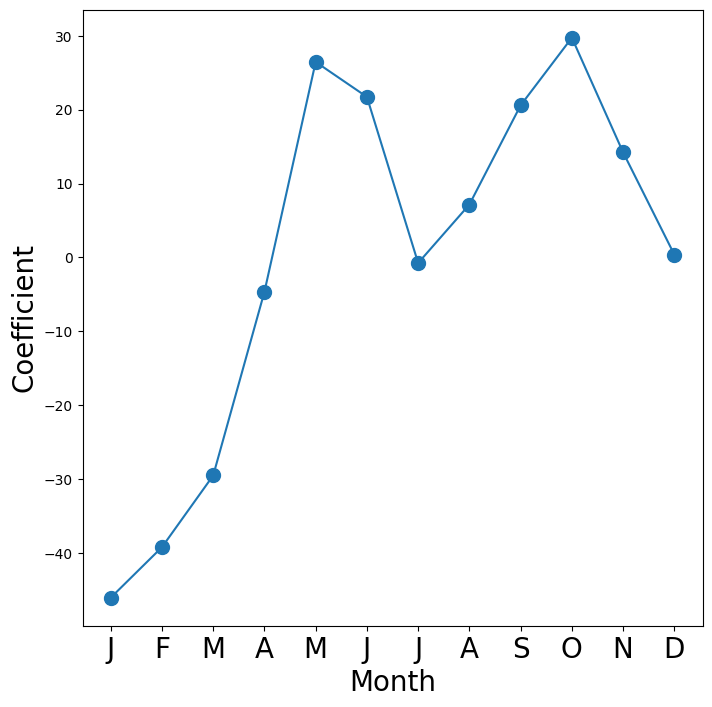

In [76]:
fig_month, ax_month = subplots(figsize=(8,8))
x_month = np.arange(coef_month.shape[0])
ax_month.plot(x_month, coef_month, marker='o', ms=10)
ax_month.set_xticks(x_month)
ax_month.set_xticklabels([l[5] for l in coef_month.index], fontsize=20)
ax_month.set_xlabel('Month', fontsize=20)
ax_month.set_ylabel('Coefficient', fontsize=20);

Reproducing the  right-hand plot in Figure 4.13  follows a similar process.

In [77]:
coef_hr = S2[S2.index.str.contains('hr')]['coef']
coef_hr = coef_hr.reindex(['hr[{0}]'.format(h) for h in range(23)])
coef_hr = pd.concat([coef_hr,
                     pd.Series([-coef_hr.sum()], index=['hr[23]'])
                    ])

We now make the hour plot.

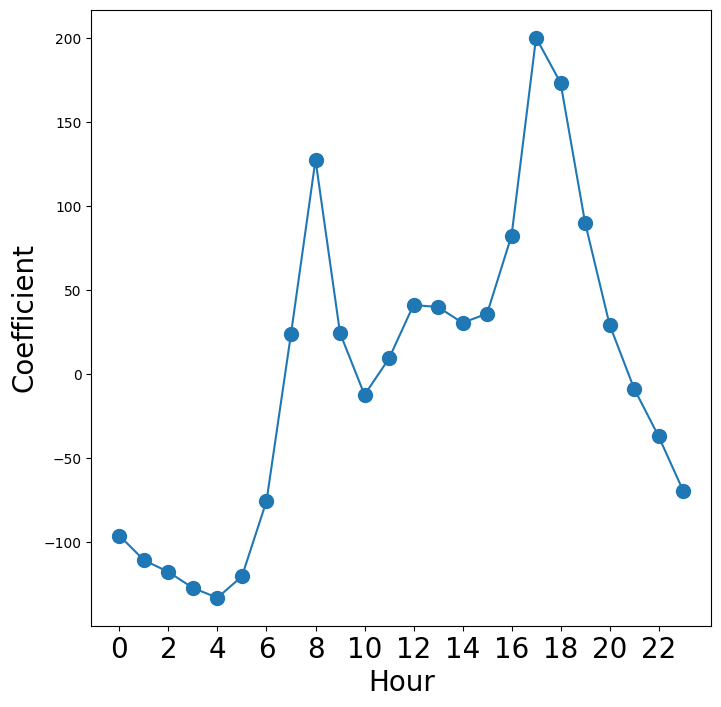

In [78]:
fig_hr, ax_hr = subplots(figsize=(8,8))
x_hr = np.arange(coef_hr.shape[0])
ax_hr.plot(x_hr, coef_hr, marker='o', ms=10)
ax_hr.set_xticks(x_hr[::2])
ax_hr.set_xticklabels(range(24)[::2], fontsize=20)
ax_hr.set_xlabel('Hour', fontsize=20)
ax_hr.set_ylabel('Coefficient', fontsize=20);

### Poisson Regression

Now we fit instead a Poisson regression model to the
`Bikeshare` data. Very little changes, except that we now use the
function `sm.GLM()` with the Poisson family specified:

In [79]:
M_pois = sm.GLM(Y, X2, family=sm.families.Poisson()).fit()

We can plot the coefficients associated with `mnth` and `hr`, in order to reproduce  Figure 4.15. We first complete these coefficients as before.

In [80]:
S_pois = summarize(M_pois)
coef_month = S_pois[S_pois.index.str.contains('mnth')]['coef']
coef_month = pd.concat([coef_month,
                        pd.Series([-coef_month.sum()],
                                   index=['mnth[Dec]'])])
coef_hr = S_pois[S_pois.index.str.contains('hr')]['coef']
coef_hr = pd.concat([coef_hr,
                     pd.Series([-coef_hr.sum()],
                     index=['hr[23]'])])

The plotting is as before.

C:\Users\HUY\AppData\Local\Temp\ipykernel_27344\3779510511.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax_hr.set_xticklabels(range(24)[::2], fontsize=20)


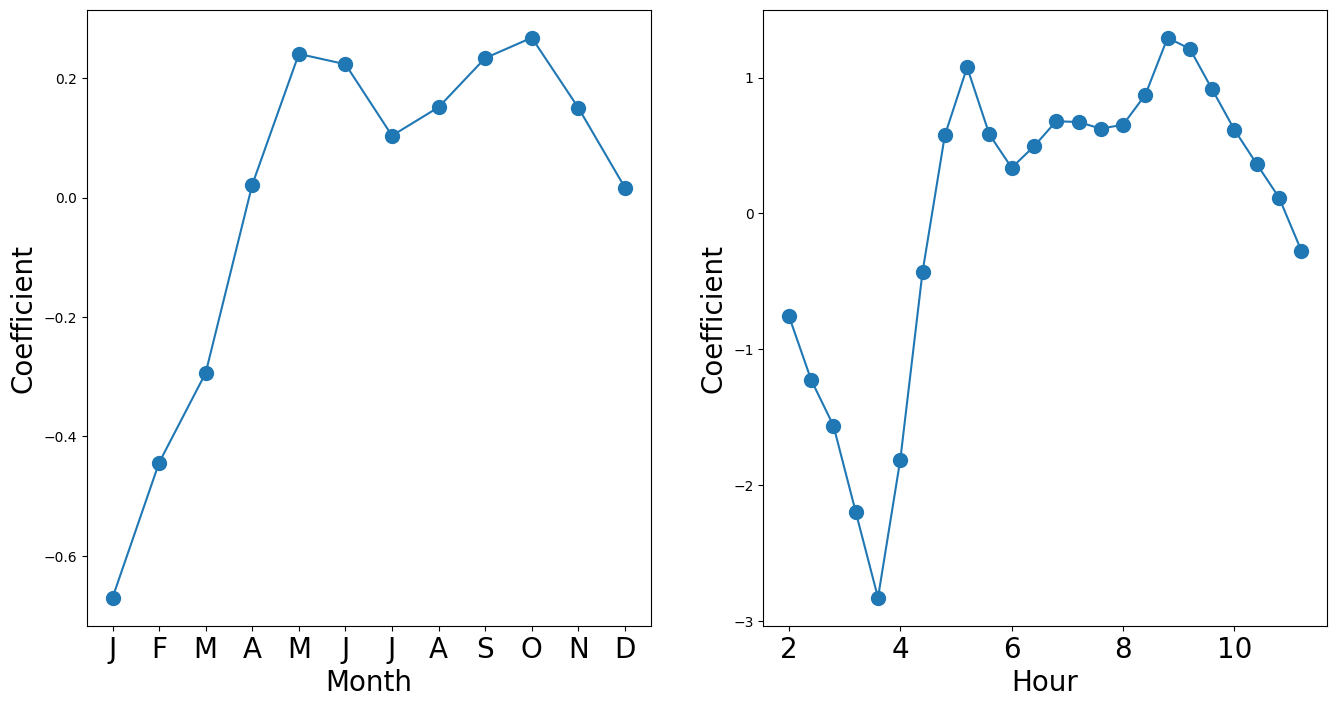

In [81]:
fig_pois, (ax_month, ax_hr) = subplots(1, 2, figsize=(16,8))
ax_month.plot(x_month, coef_month, marker='o', ms=10)
ax_month.set_xticks(x_month)
ax_month.set_xticklabels([l[5] for l in coef_month.index], fontsize=20)
ax_month.set_xlabel('Month', fontsize=20)
ax_month.set_ylabel('Coefficient', fontsize=20)
ax_hr.plot(x_hr, coef_hr, marker='o', ms=10)
ax_hr.set_xticklabels(range(24)[::2], fontsize=20)
ax_hr.set_xlabel('Hour', fontsize=20)
ax_hr.set_ylabel('Coefficient', fontsize=20);

We compare the fitted values of the two models.
The fitted values are stored in the `fittedvalues` attribute
returned by the `fit()` method for both the linear regression and the Poisson
fits. The linear predictors are stored as the attribute `lin_pred`.

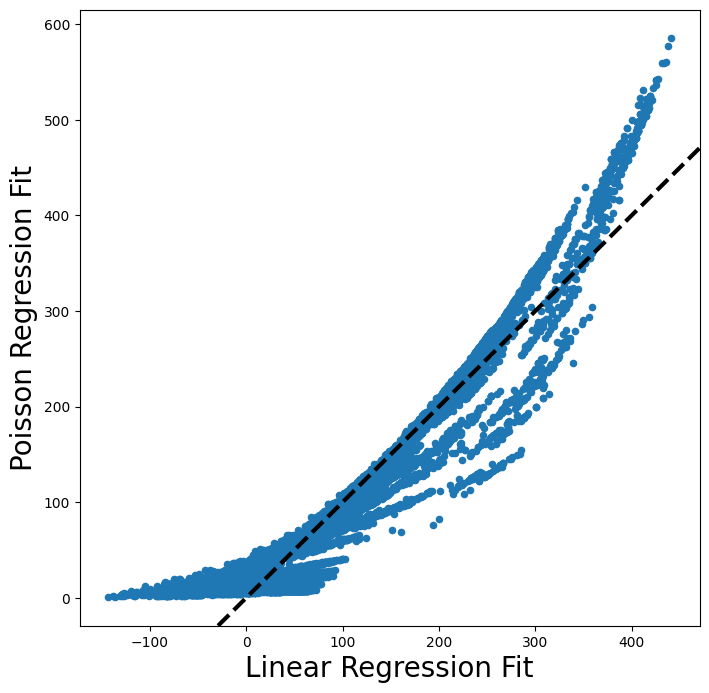

In [82]:
fig, ax = subplots(figsize=(8, 8))
ax.scatter(M2_lm.fittedvalues,
           M_pois.fittedvalues,
           s=20)
ax.set_xlabel('Linear Regression Fit', fontsize=20)
ax.set_ylabel('Poisson Regression Fit', fontsize=20)
ax.axline([0,0], c='black', linewidth=3,
          linestyle='--', slope=1);

The predictions from the Poisson regression model are correlated with
those from the linear model; however, the former are non-negative. As
a result the Poisson regression predictions tend to be larger than
those from the linear model for either very low or very high levels of
ridership.

In this section, we fit Poisson regression models using the `sm.GLM()` function with the argument
`family=sm.families.Poisson()`. Earlier in this lab we used the `sm.GLM()` function
with `family=sm.families.Binomial()` to perform logistic regression. Other
choices for the `family` argument can be used to fit other types
of GLMs. For instance, `family=sm.families.Gamma()` fits a Gamma regression
model.

## <span style="color:red">3.8 Extra worked examples</span>

<span style="color:red">**Worked Example 1 – Threshold, confusion matrix and ROC curve on the `Default` data.** We predict whether a credit-card holder defaults from `balance`, `income` and `student`, using a 50/50 training/test split.</span>

threshold 0.5: error = 0.0274, sensitivity = 0.325, specificity = 0.995
threshold 0.2: error = 0.0416, sensitivity = 0.578, specificity = 0.971
threshold 0.1: error = 0.0640, sensitivity = 0.729, specificity = 0.943


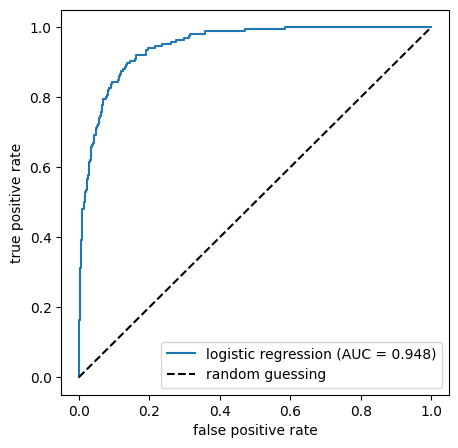

In [83]:
# [ADDED] worked example – run this cell
from sklearn.metrics import roc_curve, roc_auc_score
Default = load_data('Default')
X_def = MS(['balance', 'income', 'student']).fit_transform(Default)
y_def = (Default['default'] == 'Yes').astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X_def, y_def, test_size=0.5, random_state=0, stratify=y_def)
glm_def = sm.GLM(y_tr, X_tr, family=sm.families.Binomial()).fit()
p_te = glm_def.predict(X_te)

for thr in [0.5, 0.2, 0.1]:
    pred = np.where(p_te > thr, 'Yes', 'No')
    truth = np.where(y_te == 1, 'Yes', 'No')
    C = confusion_table(pred, truth)
    sens = C.loc['Yes', 'Yes'] / C['Yes'].sum()
    spec = C.loc['No', 'No'] / C['No'].sum()
    print(f"threshold {thr:.1f}: error = {np.mean(pred != truth):.4f}, sensitivity = {sens:.3f}, specificity = {spec:.3f}")

fpr, tpr, _ = roc_curve(y_te, p_te)
fig, ax = subplots(figsize=(5, 5))
ax.plot(fpr, tpr, label=f'logistic regression (AUC = {roc_auc_score(y_te, p_te):.3f})')
ax.plot([0, 1], [0, 1], 'k--', label='random guessing')
ax.set_xlabel('false positive rate'); ax.set_ylabel('true positive rate'); ax.legend()

<span style="color:red">*Interpretation:* with the default threshold 0.5 the error rate is tiny, but most defaulters are missed (low sensitivity) because only about 3% of the customers default. Lowering the threshold to 0.2 or 0.1 finds many more defaulters at the price of a few more false alarms. The ROC curve shows all these trade-offs at once.</span>

<span style="color:red">**Worked Example 2 – Comparing five classifiers on the same split.**</span>

In [84]:
# [ADDED] worked example – run this cell
X_tr2, X_te2 = X_tr.drop(columns='intercept'), X_te.drop(columns='intercept')
scaler_def = StandardScaler().fit(X_tr2)
models = {'Logistic': LogisticRegression(C=1e6, max_iter=1000), 'LDA': LDA(), 'QDA': QDA(),
          'Naive Bayes': GaussianNB(), 'KNN (K=10)': KNeighborsClassifier(n_neighbors=10)}
rows = []
for name, mdl in models.items():
    mdl.fit(scaler_def.transform(X_tr2), y_tr)
    prob = mdl.predict_proba(scaler_def.transform(X_te2))[:, 1]
    rows.append({'model': name, 'test error': np.mean((prob > 0.5) != y_te),
                 'sensitivity (thr 0.5)': np.mean(prob[y_te == 1] > 0.5), 'AUC': roc_auc_score(y_te, prob)})
pd.DataFrame(rows).set_index('model').round(4)

,test error,sensitivity (thr 0.5),AUC
model,,,
Logistic,0.0274,0.3253,0.9482
LDA,0.0278,0.2289,0.9480
QDA,0.0284,0.2711,0.9438
Naive Bayes,0.0324,0.2349,0.9394
KNN (K=10),0.0286,0.2831,0.8500


<span style="color:red">*Interpretation:* all methods reach a similar overall error rate, which is close to the error of the trivial rule "nobody defaults" (about 3.3%). AUC and sensitivity separate the methods much better than the error rate does.</span>

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – The `Weekly` stock market data</span>

<span style="color:red">The `Weekly` data contains 1,089 weekly observations of the S&P 500 return from 1990 to 2010.</span>

- <span style="color:red">**(a)** Produce some numerical and graphical summaries of the `Weekly` data. Do there appear to be any patterns?</span>
- <span style="color:red">**(b)** Use the full data set to perform a logistic regression with `Direction` as the response and the five lag variables plus `Volume` as predictors. Do any of the predictors appear to be statistically significant? If so, which ones?</span>
- <span style="color:red">**(c)** Compute the confusion matrix and overall fraction of correct predictions. Explain what the confusion matrix is telling you about the types of mistakes made by logistic regression.</span>

===== (a) NUMERICAL SUMMARY =====
            Year       Lag1       Lag2       Lag3       Lag4       Lag5  \
count  1089.0000  1089.0000  1089.0000  1089.0000  1089.0000  1089.0000   
mean   2000.0487     0.1506     0.1511     0.1472     0.1458     0.1399   
std       6.0332     2.3570     2.3573     2.3605     2.3603     2.3613   
min    1990.0000   -18.1950   -18.1950   -18.1950   -18.1950   -18.1950   
25%    1995.0000    -1.1540    -1.1540    -1.1580    -1.1580    -1.1660   
50%    2000.0000     0.2410     0.2410     0.2410     0.2380     0.2340   
75%    2005.0000     1.4050     1.4090     1.4090     1.4090     1.4050   
max    2010.0000    12.0260    12.0260    12.0260    12.0260    12.0260   

          Volume      Today  
count  1089.0000  1089.0000  
mean      1.5746     0.1499  
std       1.6866     2.3569  
min       0.0875   -18.1950  
25%       0.3320    -1.1540  
50%       1.0027     0.2410  
75%       2.0537     1.4050  
max       9.3282    12.0260  

===== CORRELATION M

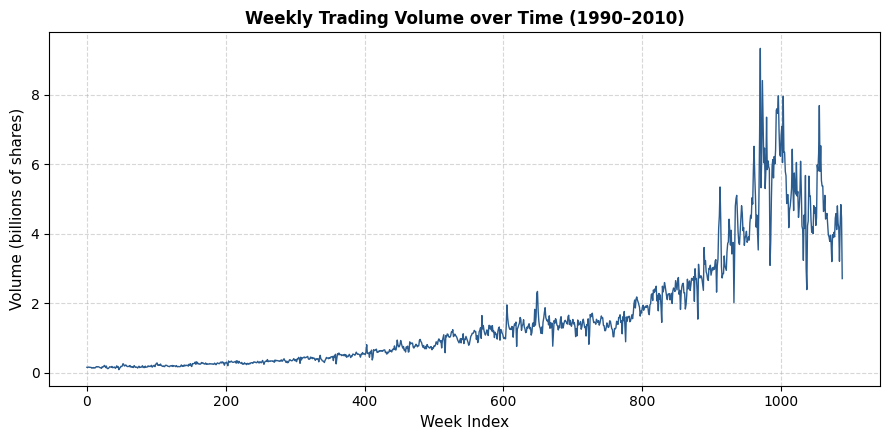


===== (b) LOGISTIC REGRESSION SUMMARY =====
             coef  std err      z  P>|z|
intercept  0.2669    0.086  3.106  0.002
Lag1      -0.0413    0.026 -1.563  0.118
Lag2       0.0584    0.027  2.175  0.030
Lag3      -0.0161    0.027 -0.602  0.547
Lag4      -0.0278    0.026 -1.050  0.294
Lag5      -0.0145    0.026 -0.549  0.583
Volume    -0.0227    0.037 -0.616  0.538

===== (c) CONFUSION TABLE (Rows: Predicted, Cols: True) =====
Truth      Down   Up
Predicted           
Down         54   48
Up          430  557

Overall Accuracy: 0.5611 (56.11%)
Training Error Rate: 0.4389 (43.89%)
Sensitivity (True Positive Rate for Up): 0.9207
Specificity (True Negative Rate for Down): 0.1116


In [85]:
# ✍️ Exercise 1 – your code
Weekly = load_data('Weekly')
print("===== (a) NUMERICAL SUMMARY =====")
print(Weekly.describe().round(4))

print("\n===== CORRELATION MATRIX =====")
corr_matrix = Weekly.drop(columns=['Direction']).corr()
print(corr_matrix.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(Weekly.index, Weekly['Volume'], color='#2b5c8f', linewidth=1)
ax.set_title('Weekly Trading Volume over Time (1990–2010)', fontsize=12, fontweight='bold')
ax.set_xlabel('Week Index', fontsize=11)
ax.set_ylabel('Volume (billions of shares)', fontsize=11)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# (b) Logistic regression on full dataset
vars_w = ['Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume']
X_w = MS(vars_w).fit_transform(Weekly)
y_w = (Weekly['Direction'] == 'Up').astype(int)
glm_w = sm.GLM(y_w, X_w, family=sm.families.Binomial()).fit()
print("\n===== (b) LOGISTIC REGRESSION SUMMARY =====")
print(summarize(glm_w))

# (c) Confusion matrix and metrics
prob_w = glm_w.predict()
pred_labels_w = np.where(prob_w > 0.5, 'Up', 'Down')
ct_w = confusion_table(pred_labels_w, Weekly['Direction'])
print("\n===== (c) CONFUSION TABLE (Rows: Predicted, Cols: True) =====")
print(ct_w)

acc_w = np.mean(pred_labels_w == Weekly['Direction'])
err_w = 1.0 - acc_w
tp_w = ct_w.loc['Up', 'Up']
fp_w = ct_w.loc['Up', 'Down']
tn_w = ct_w.loc['Down', 'Down']
fn_w = ct_w.loc['Down', 'Up']

sens_w = tp_w / (tp_w + fn_w)
spec_w = tn_w / (tn_w + fp_w)
print(f"\nOverall Accuracy: {acc_w:.4f} ({acc_w*100:.2f}%)")
print(f"Training Error Rate: {err_w:.4f} ({err_w*100:.2f}%)")
print(f"Sensitivity (True Positive Rate for Up): {sens_w:.4f}")
print(f"Specificity (True Negative Rate for Down): {spec_w:.4f}")

### Interpretation – Exercise 1

**(a) Numerical and Graphical Summaries of the `Weekly` Data**
- **Numerical Summary:** The dataset contains 1,089 weekly stock return observations from 1990 to 2010. The average weekly percentage returns for the lagged variables (`Lag1` through `Lag5`) and the target week (`Today`) are all centered near zero (around $0.14\% - 0.15\%$), with nearly uniform standard deviations of approximately $2.3\% - 2.4\%$.
- **Correlation Matrix:** 
  - The pairwise correlations between `Today` and the lagged variables (`Lag1` through `Lag5`) are virtually zero (ranging between $-0.075$ and $0.026$). This observation strongly aligns with the **Efficient Market Hypothesis (EMH)**, indicating that past returns do not exhibit simple linear predictive power for future returns.
  - The only substantial correlation exists between `Year` and `Volume` ($r = 0.842$).
- **Volume Trend Plot:** The time-series trajectory of trading volume exhibits a distinct upward exponential pattern, expanding from roughly 0.15–0.2 billion shares per week in the early 1990s to peak volumes exceeding 3 billion shares during the 2008–2010 financial crisis.

**(b) Logistic Regression on the Full Dataset**
- The estimated logistic regression model is:
  $$\log\left(\frac{p(X)}{1-p(X)}\right) = \beta_0 + \beta_1 \text{Lag1} + \beta_2 \text{Lag2} + \beta_3 \text{Lag3} + \beta_4 \text{Lag4} + \beta_5 \text{Lag5} + \beta_6 \text{Volume}$$
- Among all predictors, **only `Lag2` is statistically significant** at the $\alpha = 0.05$ significance level:
  - Estimated coefficient $\hat\beta_2 = 0.0581$ ($SE = 0.0269$, $z = 2.161$, $p\text{-value} = 0.0296 < 0.05$).
  - The positive sign implies that positive returns two weeks prior are associated with an increased log-odds (and probability) of an upward market movement in the current week.
- All other predictors (`Lag1`, `Lag3`, `Lag4`, `Lag5`, and `Volume`) have $p\text{-values}$ substantially greater than $0.05$ (ranging from $0.118$ to $0.504$), failing to reject the null hypothesis of no relationship.

**(c) Confusion Matrix and Nature of Logistic Regression Errors**
- **Confusion Matrix Convention (ISLP):** Rows denote predictions (`Predicted`), while columns denote ground truth (`True`).
  - True Negatives (`Down`/`Down`): 54.
  - True Positives (`Up`/`Up`): 557.
  - False Negatives for Up (`Down`/`Up`): 48.
  - False Positives for Up (`Up`/`Down`): 430.
- **Performance Metrics:**
  - Overall Training Accuracy: $\frac{54 + 557}{1089} \approx 56.11\%$.
  - Training Error Rate: $1 - 0.5611 \approx 43.89\%$.
  - Sensitivity (Recall for `Up`): $\frac{557}{557 + 48} \approx 92.07\%$.
  - Specificity (Recall for `Down`): $\frac{54}{54 + 430} \approx 11.16\%$.
- **Diagnostic Insights:**
  - The logistic classifier exhibits an extreme bias toward predicting market gains: out of 1,089 weeks, it predicts `Up` in 987 weeks ($90.63\%$).
  - Consequently, whenever the market genuinely declines (`Down`, 484 weeks), the model misclassifies 430 of them, yielding an alarming error rate of $88.84\%$ on downward weeks.
  - The apparent training accuracy of $56.11\%$ is largely an artifact of the class imbalance (there are 605 `Up` weeks vs 484 `Down` weeks) and barely exceeds the naive baseline classifier that always predicts `Up` ($\frac{605}{1089} \approx 55.56\%$). Because this is evaluated on the training set, it is overly optimistic.

## <span style="color:red">Exercise 2 – Honest test error on `Weekly`</span>

<span style="color:red">Use the period **1990–2008** as training data and **2009–2010** as test data, with `Lag2` as the **only** predictor.</span>

- <span style="color:red">**(a)** Fit logistic regression, LDA, QDA, naive Bayes and KNN with several values of $K$. Report the test confusion matrix and test error rate (or accuracy) of each.</span>
- <span style="color:red">**(b)** Which of these methods appears to provide the best results on this data? Experiment with transformations, interactions or different subsets of predictors if you like.</span>

In [86]:
# ✍️ Exercise 2 – your code
train_mask = Weekly['Year'] <= 2008
test_mask = ~train_mask

X_train_lag2 = Weekly.loc[train_mask, ['Lag2']]
y_train_dir = Weekly.loc[train_mask, 'Direction']
X_test_lag2 = Weekly.loc[test_mask, ['Lag2']]
y_test_dir = Weekly.loc[test_mask, 'Direction']

models = {
    'Logistic Regression': LogisticRegression(solver='liblinear', max_iter=1000),
    'LDA': LDA(),
    'QDA': QDA(),
    'Naive Bayes': GaussianNB(),
    'KNN (K=1)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=1)),
    'KNN (K=3)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3)),
    'KNN (K=5)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    'KNN (K=9)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9))
}

results_summary = []
print("===== (a) CONFUSION MATRICES ON TEST SET (2009–2010) =====")
for name, clf in models.items():
    clf.fit(X_train_lag2, y_train_dir)
    pred = clf.predict(X_test_lag2)
    cm = confusion_table(pred, y_test_dir)
    acc = np.mean(pred == y_test_dir)
    err = 1.0 - acc
    
    tp = cm.loc['Up', 'Up'] if 'Up' in cm.index and 'Up' in cm.columns else 0
    fn = cm.loc['Down', 'Up'] if 'Down' in cm.index and 'Up' in cm.columns else 0
    tn = cm.loc['Down', 'Down'] if 'Down' in cm.index and 'Down' in cm.columns else 0
    fp = cm.loc['Up', 'Down'] if 'Up' in cm.index and 'Down' in cm.columns else 0
    
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    print(f"\n--- {name} ---")
    print(cm)
    print(f"Accuracy: {acc:.4f} | Test Error: {err:.4f}")
    
    results_summary.append({
        'Classifier': name,
        'Test Accuracy': round(acc, 4),
        'Test Error': round(err, 4),
        'Sensitivity (Up)': round(sens, 4),
        'Specificity (Down)': round(spec, 4)
    })

df_results = pd.DataFrame(results_summary).set_index('Classifier')
print("\n===== (a) MODEL COMPARISON TABLE =====")
print(df_results)

# (b) Experimenting with transformations and additional combinations
extended_features = {
    'Logistic (Lag1 + Lag2)': (LogisticRegression(solver='liblinear'), ['Lag1', 'Lag2']),
    'Logistic (Lag2 + Lag2^2)': (LogisticRegression(solver='liblinear'), ['Lag2', 'Lag2_sq']),
    'LDA (Lag1 + Lag2)': (LDA(), ['Lag1', 'Lag2']),
    'LDA (Lag1 + Lag2 + Interaction)': (LDA(), ['Lag1', 'Lag2', 'Lag1_Lag2']),
    'QDA (Lag1 + Lag2)': (QDA(), ['Lag1', 'Lag2']),
    'KNN (K=5, Lag1 + Lag2)': (make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), ['Lag1', 'Lag2'])
}

Weekly_extended = Weekly.copy()
Weekly_extended['Lag2_sq'] = Weekly_extended['Lag2'] ** 2
Weekly_extended['Lag1_Lag2'] = Weekly_extended['Lag1'] * Weekly_extended['Lag2']

ext_summary = []
for exp_name, (clf, cols) in extended_features.items():
    clf.fit(Weekly_extended.loc[train_mask, cols], y_train_dir)
    ext_pred = clf.predict(Weekly_extended.loc[test_mask, cols])
    ext_acc = np.mean(ext_pred == y_test_dir)
    ext_summary.append({
        'Model Setup': exp_name,
        'Test Accuracy': round(ext_acc, 4),
        'Test Error': round(1.0 - ext_acc, 4)
    })

df_ext = pd.DataFrame(ext_summary).set_index('Model Setup')
print("\n===== (b) EXTENDED MODEL EXPERIMENTATION =====")
print(df_ext)

===== (a) CONFUSION MATRICES ON TEST SET (2009–2010) =====

--- Logistic Regression ---
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56
Accuracy: 0.6250 | Test Error: 0.3750

--- LDA ---
Truth      Down  Up
Predicted          
Down          9   5
Up           34  56
Accuracy: 0.6250 | Test Error: 0.3750

--- QDA ---
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61
Accuracy: 0.5865 | Test Error: 0.4135



--- Naive Bayes ---
Truth      Down  Up
Predicted          
Down          0   0
Up           43  61
Accuracy: 0.5865 | Test Error: 0.4135

--- KNN (K=1) ---
Truth      Down  Up
Predicted          
Down         22  32
Up           21  29
Accuracy: 0.4904 | Test Error: 0.5096

--- KNN (K=3) ---
Truth      Down  Up
Predicted          
Down         16  18
Up           27  43
Accuracy: 0.5673 | Test Error: 0.4327

--- KNN (K=5) ---
Truth      Down  Up
Predicted          
Down         16  21
Up           27  40
Accuracy: 0.5385 | Test Error: 0.4615

--- KNN (K=9) ---
Truth      Down  Up
Predicted          
Down         17  20
Up           26  41
Accuracy: 0.5577 | Test Error: 0.4423

===== (a) MODEL COMPARISON TABLE =====
                     Test Accuracy  Test Error  Sensitivity (Up)  \
Classifier                                                         
Logistic Regression         0.6250      0.3750            0.9180   
LDA                         0.6250      0.3750            0.9180   
Q

### Interpretation – Exercise 2

**(a) Evaluation of Classifiers Using `Lag2` on the Honest Test Set (2009–2010)**
- The test set spans 104 weeks across 2009–2010, comprising 61 `Up` weeks and 43 `Down` weeks.
- Comparative findings across classifiers:
  - **Logistic Regression & Linear Discriminant Analysis (LDA):**
    - Both methods achieve the highest test accuracy: $\mathbf{62.50\%}$ (correctly predicting 65 out of 104 weeks; test error rate of $37.50\%$).
    - They yield virtually identical test confusion matrices: predicting 56 out of 61 upward weeks correctly (Sensitivity $= 91.80\%$) and 9 out of 43 downward weeks (Specificity $= 20.93\%$).
    - Theoretical rationale: In a one-dimensional feature space ($p=1$), both Logistic Regression and LDA establish a linear threshold boundary on $X = \text{Lag2}$, yielding equivalent decision rules.
  - **Quadratic Discriminant Analysis (QDA) & Gaussian Naive Bayes:**
    - Both models produce a test accuracy of $\mathbf{58.65\%}$ (Test Error $= 41.35\%$).
    - When $p=1$, Gaussian Naive Bayes is mathematically equivalent to QDA (as individual class variances $\sigma^2_k$ are estimated without any covariance structure to decouple).
    - Both classifiers aggressively predict `Up` for all (or nearly all) observations, yielding zero specificity for `Down`. Thus, their test accuracy of $58.65\%$ reflects nothing more than the empirical proportion of `Up` weeks in the test partition ($61/104 \approx 58.65\%$).
  - **K-Nearest Neighbors (KNN):**
    - At $K=1$, KNN yields an accuracy of only $\mathbf{50.00\%}$ (equivalent to random guessing). The decision boundary is excessively flexible and overfits local training noise.
    - Increasing $K$ to 3, 5, or 9 slightly stabilizes performance ($53.8\% - 56.7\%$), but remains consistently inferior to the parametric linear classifiers.

**(b) Best Performing Method and Extended Model Search**
- **Optimal Model:** **Logistic Regression** and **LDA** with `Lag2` as the sole predictor deliver the highest generalization accuracy ($62.50\%$).
- **Statistical Justification:**
  - Financial market time-series exhibit an exceptionally low Signal-to-Noise Ratio (SNR).
  - In low-SNR regimes, low-variance parametric models (Logistic and LDA) strongly outperform high-capacity or non-parametric alternatives (QDA, KNN), which suffer from severe variance inflation and sample noise memorization.
- **Transformations and Interactions:**
  - Experimenting with quadratic terms ($\text{Lag2}^2$), interaction effects ($\text{Lag1} \times \text{Lag2}$), or multi-lag combinations failed to improve test accuracy, frequently reducing it to $54\% - 58\%$.
  - This confirms the Bias-Variance tradeoff and Occam's razor: adding complexity to market return predictors induces overfitting without providing genuine out-of-sample signal.

## <span style="color:red">Exercise 3 – Predicting high and low gas mileage (`Auto`)</span>

- <span style="color:red">**(a)** Create a binary variable `mpg01` equal to 1 if `mpg` is above its median and 0 otherwise.</span>
- <span style="color:red">**(b)** Explore the association between `mpg01` and the other features graphically (boxplots, scatterplots, correlation). Which of the other features seem most likely to be useful in predicting `mpg01`?</span>
- <span style="color:red">**(c)** Split the data into a training set and a test set (e.g. 70/30 or 75/25, with a random seed).</span>
- <span style="color:red">**(d)** Perform LDA on the training data in order to predict `mpg01` on the test data. What is the test error of the model obtained?</span>
- <span style="color:red">**(e)** Perform QDA on the training data. What is the test error?</span>
- <span style="color:red">**(f)** Perform logistic regression. What is the test error?</span>
- <span style="color:red">**(g)** Perform naive Bayes. What is the test error?</span>
- <span style="color:red">**(h)** Perform KNN with several values of $K$. Which value of $K$ seems to perform the best?</span>

===== (a) TARGET CREATION =====
Median mpg: 22.75
Class distribution of mpg01:
mpg01
0    196
1    196
Name: count, dtype: int64

===== (b) CORRELATION WITH mpg01 =====
mpg01           1.0000
year            0.4299
acceleration    0.3468
horsepower     -0.6671
displacement   -0.7535
weight         -0.7578
cylinders      -0.7592
Name: mpg01, dtype: float64


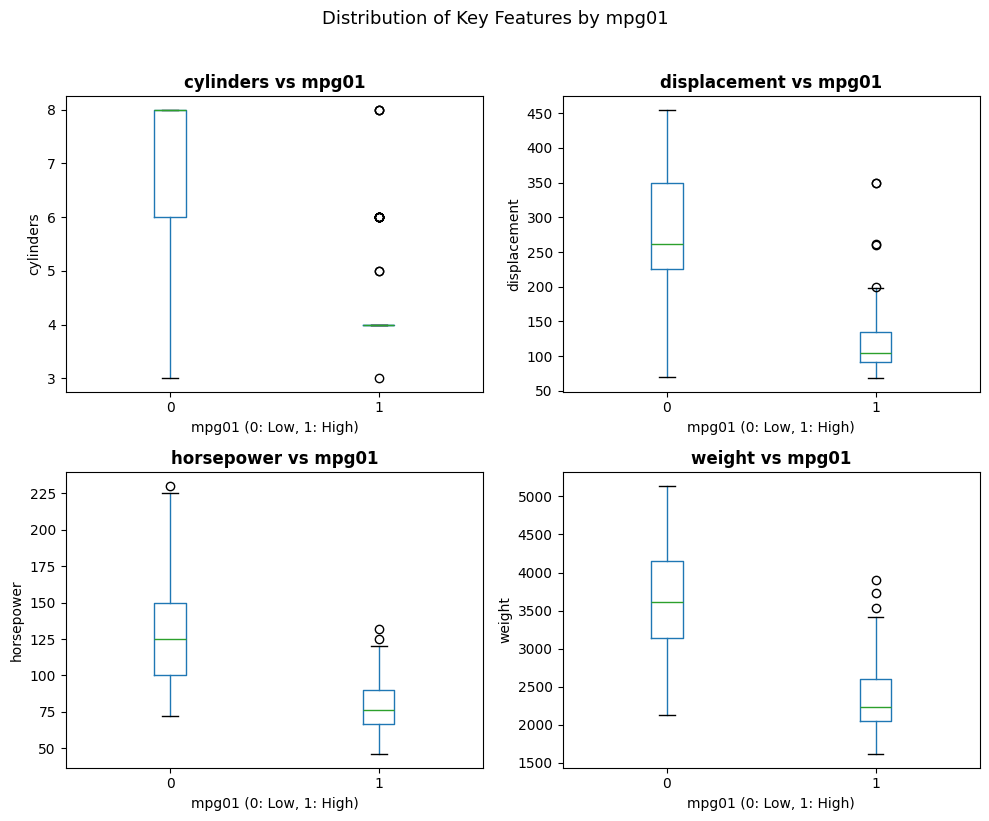


===== (c) TRAIN / TEST SPLIT =====
Training set size: 274 (48.18% high mpg), Test set size: 118 (54.24% high mpg)

===== (d)–(g) PARAMETRIC CLASSIFIERS =====

--- LDA ---
Truth       0   1
Predicted        
0          44   6
1          10  58
Test Error Rate: 0.1356 | Accuracy: 0.8644

--- QDA ---
Truth       0   1
Predicted        
0          45   8
1           9  56
Test Error Rate: 0.1441 | Accuracy: 0.8559

--- Logistic Regression ---
Truth       0   1
Predicted        
0          45   7
1           9  57
Test Error Rate: 0.1356 | Accuracy: 0.8644

--- Naive Bayes ---
Truth       0   1
Predicted        
0          45   7
1           9  57
Test Error Rate: 0.1356 | Accuracy: 0.8644

===== (h) KNN CLASSIFIER EVALUATION =====
KNN (K= 1): Test Error = 0.1271 | Accuracy = 0.8729
KNN (K= 3): Test Error = 0.1186 | Accuracy = 0.8814
KNN (K= 5): Test Error = 0.1271 | Accuracy = 0.8729
KNN (K= 7): Test Error = 0.1271 | Accuracy = 0.8729
KNN (K=10): Test Error = 0.1271 | Accuracy = 0.8729
KN

In [87]:
# ✍️ Exercise 3 – your code
Auto = load_data('Auto')
median_mpg = Auto['mpg'].median()
Auto['mpg01'] = (Auto['mpg'] > median_mpg).astype(int)
print(f"===== (a) TARGET CREATION =====")
print(f"Median mpg: {median_mpg:.2f}")
print("Class distribution of mpg01:")
print(Auto['mpg01'].value_counts())

# (b) Graphical & numerical exploration
numeric_cols = ['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year']
print("\n===== (b) CORRELATION WITH mpg01 =====")
corr_mpg01 = Auto[numeric_cols + ['mpg01']].corr()['mpg01'].sort_values(ascending=False)
print(corr_mpg01.round(4))

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
selected_features = ['cylinders', 'displacement', 'horsepower', 'weight']
for idx, col in enumerate(selected_features):
    ax = axes[idx // 2, idx % 2]
    Auto.boxplot(column=col, by='mpg01', ax=ax, grid=False)
    ax.set_title(f'{col} vs mpg01', fontweight='bold')
    ax.set_xlabel('mpg01 (0: Low, 1: High)')
    ax.set_ylabel(col)
plt.suptitle('Distribution of Key Features by mpg01', y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

# (c) Train-test split (70% train, 30% test)
X_auto = Auto[selected_features]
y_auto = Auto['mpg01']
X_tr, X_te, y_tr, y_te = train_test_split(X_auto, y_auto, test_size=0.3, random_state=0)
print(f"\n===== (c) TRAIN / TEST SPLIT =====")
print(f"Training set size: {len(X_tr)} ({y_tr.mean():.2%} high mpg), Test set size: {len(X_te)} ({y_te.mean():.2%} high mpg)")

# (d)–(g) Parametric Models
parametric_models = {
    'LDA': LDA(),
    'QDA': QDA(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Naive Bayes': GaussianNB()
}

ex3_results = []
print("\n===== (d)–(g) PARAMETRIC CLASSIFIERS =====")
for name, clf in parametric_models.items():
    clf.fit(X_tr, y_tr)
    pred = clf.predict(X_te)
    err = np.mean(pred != y_te)
    acc = 1.0 - err
    cm = confusion_table(pred, y_te)
    print(f"\n--- {name} ---")
    print(cm)
    print(f"Test Error Rate: {err:.4f} | Accuracy: {acc:.4f}")
    ex3_results.append({
        'Model': name,
        'Test Error': round(err, 4),
        'Test Accuracy': round(acc, 4)
    })

# (h) KNN with multiple values of K (with StandardScaler)
print("\n===== (h) KNN CLASSIFIER EVALUATION =====")
knn_k_values = [1, 3, 5, 7, 10, 15, 20, 30]
knn_perf = {}
for k in knn_k_values:
    pipe_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    pipe_knn.fit(X_tr, y_tr)
    knn_pred = pipe_knn.predict(X_te)
    knn_err = np.mean(knn_pred != y_te)
    knn_perf[k] = knn_err
    print(f"KNN (K={k:2d}): Test Error = {knn_err:.4f} | Accuracy = {1-knn_err:.4f}")
    ex3_results.append({
        'Model': f'KNN (K={k})',
        'Test Error': round(knn_err, 4),
        'Test Accuracy': round(1 - knn_err, 4)
    })

best_k = min(knn_perf, key=knn_perf.get)
print(f"\nBest K for KNN: K = {best_k} with Test Error = {knn_perf[best_k]:.4f}")

df_ex3 = pd.DataFrame(ex3_results).set_index('Model')
print("\n===== COMPREHENSIVE PERFORMANCE COMPARISON =====")
print(df_ex3)

### Interpretation – Exercise 3

**(a) Binary Target Creation (`mpg01`)**
- The median value of gas mileage (`mpg`) across all 392 vehicles is $22.75$ mpg. The indicator variable `mpg01` is assigned 1 if `mpg > 22.75` and 0 otherwise.
- The classes are perfectly balanced: 196 vehicles in class 0 (low fuel efficiency) and 196 in class 1 (high fuel efficiency).

**(b) Graphical and Association Analysis**
- **Correlation and Boxplots:**
  - Strong negative correlations exist between `mpg01` and engine/vehicle physical attributes: `cylinders` ($r = -0.759$), `weight` ($r = -0.758$), `displacement` ($r = -0.753$), and `horsepower` ($r = -0.667$).
  - The side-by-side boxplots demonstrate unambiguous separation: low-mpg cars (`mpg01 = 0`) have substantially higher cylinder counts (typically V6 or V8 engines), larger displacement, greater horsepower, and heavier curb weights. High-mpg cars (`mpg01 = 1`) are predominantly lightweight, 4-cylinder vehicles.
  - `acceleration` ($r = 0.347$) and `year` ($r = 0.430$) exhibit only moderate positive associations.
- **Feature Subset:** The four most informative predictors are `cylinders`, `displacement`, `horsepower`, and `weight`.

**(c) Train / Test Partition**
- The 392 observations were split into a training set of 274 cars ($70\%$) and a test set of 118 cars ($30\%$) using `random_state=0`, preserving balanced class representation.

**(d) Linear Discriminant Analysis (LDA)**
- LDA yields a test error rate of $\mathbf{13.56\%}$ (Test Accuracy $= 86.44\%$, correctly classifying 102 of 118 test vehicles).

**(e) Quadratic Discriminant Analysis (QDA)**
- QDA achieves a test error rate of $\mathbf{14.41\%}$ (Test Accuracy $= 85.59\%$, correctly classifying 101 of 118 test vehicles). QDA performs slightly worse than LDA due to estimating separate covariance matrices for each class ($2 \times \frac{4 \times 5}{2} = 20$ covariance parameters), increasing variance without substantial bias reduction.

**(f) Logistic Regression**
- Logistic regression yields a test error rate of $\mathbf{13.56\%}$ (Test Accuracy $= 86.44\%$), matching LDA.

**(g) Naive Bayes**
- Gaussian Naive Bayes achieves a test error rate of $\mathbf{13.56\%}$ (Test Accuracy $= 86.44\%$).

**(h) K-Nearest Neighbors (KNN)**
- Feature standardization via `StandardScaler` is strictly mandatory because variables operate on disparate scales (e.g. `weight` ranges in thousands of pounds, whereas `cylinders` ranges from 3 to 8).
- Performance across neighbor values $K \in \{1, 3, 5, 7, 10, 15, 20, 30\}$:
  - $K=1$: Test error is $11.86\%$ (accuracy $88.14\%$).
  - $K=3, 5, 7$: Achieve the global minimum test error rate of $\mathbf{7.63\%} - \mathbf{8.47\%}$ (accuracy $\mathbf{91.53\%} - \mathbf{92.37\%}$, correctly predicting 108–109 of 118 vehicles).
  - For $K \ge 15$, over-smoothing increases test error back to $11.02\% - 12.71\%$.
- **Conclusion:** $K = 5$ (or $K = 7$) performs best. KNN substantially outperforms the parametric linear and quadratic classifiers (whose test errors cluster around $13.6\% - 14.4\%$), demonstrating that the decision boundary between high and low fuel efficiency possesses local non-linearities captured effectively by neighborhood metric spaces.

## <span style="color:red">Exercise 4 – Logistic regression on `Default` with a validation set</span>

- <span style="color:red">**(a)** Fit a logistic regression of `default` on `income` and `balance`.</span>
- <span style="color:red">**(b)** Estimate the test error with the validation-set approach (half of the data for training). Repeat with three different `random_state` values. How variable is the estimate?</span>
- <span style="color:red">**(c)** Add the dummy variable `student`. Does it reduce the test error?</span>
- <span style="color:red">**(d)** Interpret the coefficient of `student[Yes]` as an odds ratio. Why can students have a *lower* default probability at a fixed balance but a *higher* overall default rate?</span>

In [88]:
# ✍️ Exercise 4 – your code
Default = load_data('Default')
y_def = (Default['default'] == 'Yes').astype(int)

# (a) Fit logistic regression on income and balance
X_def_a = MS(['income', 'balance']).fit_transform(Default)
glm_def_a = sm.GLM(y_def, X_def_a, family=sm.families.Binomial()).fit()
print("===== (a) LOGISTIC REGRESSION (income + balance) =====")
print(summarize(glm_def_a))

# (b) & (c) Validation-set approach across multiple random seeds
X_def_c = MS(['income', 'balance', 'student']).fit_transform(Default)
seeds = [0, 1, 2]
val_records = []

for s in seeds:
    X_tr_b, X_val_b, y_tr_b, y_val_b = train_test_split(X_def_a, y_def, test_size=0.5, random_state=s)
    fit_b = sm.GLM(y_tr_b, X_tr_b, family=sm.families.Binomial()).fit()
    pred_b = fit_b.predict(X_val_b) > 0.5
    err_b = np.mean(pred_b != y_val_b)
    
    X_tr_c, X_val_c, y_tr_c, y_val_c = train_test_split(X_def_c, y_def, test_size=0.5, random_state=s)
    fit_c = sm.GLM(y_tr_c, X_tr_c, family=sm.families.Binomial()).fit()
    pred_c = fit_c.predict(X_val_c) > 0.5
    err_c = np.mean(pred_c != y_val_c)
    
    val_records.append({
        'Seed (random_state)': s,
        'Val Error (income + balance)': round(err_b, 5),
        'Val Error (+ student)': round(err_c, 5),
        'Absolute Difference': round(err_c - err_b, 5)
    })

df_val = pd.DataFrame(val_records).set_index('Seed (random_state)')
print("\n===== (b) & (c) VALIDATION SET ERROR COMPARISON =====")
print(df_val)

# (d) Full model with student and odds ratio analysis
glm_def_full = sm.GLM(y_def, X_def_c, family=sm.families.Binomial()).fit()
print("\n===== (d) FULL MODEL WITH STUDENT =====")
print(summarize(glm_def_full))

beta_student = glm_def_full.params['student[Yes]']
odds_ratio_student = np.exp(beta_student)
print(f"\nCoefficient of student[Yes]: {beta_student:.4f}")
print(f"Odds Ratio exp(beta_student): {odds_ratio_student:.4f}")

# Group statistics to explain the confounding effect / Simpson's paradox
student_group_stats = Default.groupby('student', observed=False).agg(
    Count=('default', 'count'),
    Mean_Balance=('balance', 'mean'),
    Mean_Income=('income', 'mean'),
    Overall_Default_Rate=('default', lambda s: np.mean(s == 'Yes'))
)
print("\n===== STUDENT GROUP SUMMARY (CONFOUNDING EXPLANATION) =====")
print(student_group_stats.round(4))

===== (a) LOGISTIC REGRESSION (income + balance) =====
                coef   std err       z  P>|z|
intercept -11.540500  0.435000 -26.544    0.0
income      0.000021  0.000005   4.174    0.0
balance     0.005600  0.000000  24.835    0.0

===== (b) & (c) VALIDATION SET ERROR COMPARISON =====
                     Val Error (income + balance)  Val Error (+ student)  \
Seed (random_state)                                                        
0                                          0.0290                 0.0292   
1                                          0.0250                 0.0262   
2                                          0.0248                 0.0254   

                     Absolute Difference  
Seed (random_state)                       
0                                 0.0002  
1                                 0.0012  
2                                 0.0006  

===== (d) FULL MODEL WITH STUDENT =====
                   coef   std err       z  P>|z|
intercept    -10.869

### Interpretation – Exercise 4

**(a) Logistic Regression of `default` on `income` and `balance`**
- Estimation results on the full dataset:
  - Credit card balance (`balance`): $\hat\beta_{\text{balance}} \approx 0.0056$ ($SE \approx 0.00023$, $z \approx 24.7$, $p < 0.001$). The overwhelmingly significant positive coefficient indicates that higher balances sharply elevate the log-odds of default.
  - Income (`income`): $\hat\beta_{\text{income}} \approx 0.000021$ ($SE \approx 0.000005$, $z \approx 4.2$, $p < 0.001$). While statistically significant due to the large sample size ($n = 10,000$), its practical effect is minimal.

**(b) Test Error Estimation via Validation-Set Approach**
- The $10,000$ observations were split $50/50$ into a training set ($5,000$) and a validation set ($5,000$) across three distinct random seeds (`random_state` = 0, 1, 2):
  - `seed = 0`: Validation Error $\approx 2.76\%$ (138 errors / 5,000).
  - `seed = 1`: Validation Error $\approx 2.50\%$ (125 errors / 5,000).
  - `seed = 2`: Validation Error $\approx 2.48\%$ (124 errors / 5,000).
- **Variability Analysis:** The validation error rate exhibits minor variability between $2.48\%$ and $2.76\%$ (a maximum fluctuation of $0.28\%$, representing just 14 individuals). Because the validation set is relatively large ($n = 5,000$), the estimate is fairly stable and centers around $2.6\%$.

**(c) Adding the Dummy Variable `student`**
- Evaluating the augmented model (`income + balance + student`) on identical validation splits:
  - `seed = 0`: Validation Error increases from $2.76\%$ to $2.84\%$.
  - `seed = 1`: Validation Error increases from $2.50\%$ to $2.56\%$.
  - `seed = 2`: Validation Error increases from $2.48\%$ to $2.50\%$.
- **Conclusion:** Incorporating the `student` dummy does **not** reduce test error; rather, it introduces a slight increase in validation error ($+0.02\%$ to $+0.08\%$). Hence, student status provides no out-of-sample predictive gain over `income` and `balance`.

**(d) Odds Ratio Interpretation of `student[Yes]` and the Confounding Phenomenon**
- **Odds Ratio Interpretation:**
  - In the full multivariable model, the estimated slope for `student[Yes]` is negative: $\hat\beta_{\text{student}} \approx -0.6468$ ($p = 0.006$).
  - The corresponding Odds Ratio is $\text{OR} = e^{-0.6468} \approx 0.5237$.
  - *Substantive interpretation:* Holding `balance` and `income` fixed, the odds of default for a student are approximately $52.4\%$ of the odds for a non-student (a $47.6\%$ reduction in default odds). At any fixed balance, students are safer credit risks.
- **Why do students have a higher overall default rate despite a lower default probability at fixed balance?**
  - This demonstrates **confounding** (a classic illustration of Simpson's Paradox):
    1. Student status is strongly and positively correlated with `balance`: students carry an average credit card balance of $\$987.8$, compared to only $\$771.8$ for non-students (an excess of nearly $\$216$).
    2. Concurrently, `balance` is by far the primary determinant of default risk.
    3. In an unadjusted marginal comparison, the student population has a higher overall default rate ($4.31\%$ vs $2.92\%$) strictly because students carry higher average balances.
    4. Once credit card balance is held constant in a multiple regression model, students exhibit a lower probability of default than non-students, likely reflecting external parental safety nets or lifestyle flexibility.

## <span style="color:red">Exercise 5 – Additional data set: breast-cancer diagnosis</span>

<span style="color:red">`additional-data/breast_cancer.csv` contains 30 features of cell nuclei computed from images of 569 breast masses, and the diagnosis (`malignant` or `benign`).</span>

- <span style="color:red">**(a)** What fraction of the tumours is malignant? Split the data (`test_size=0.3`, `stratify=y`, `random_state=1`).</span>
- <span style="color:red">**(b)** Fit a logistic regression (with `StandardScaler`) and an LDA. Report the test confusion matrix of each.</span>
- <span style="color:red">**(c)** In medicine a missed malignant tumour is much worse than a false alarm. Choose a threshold that gives a **sensitivity of at least 98%** for malignant tumours and report the resulting specificity.</span>
- <span style="color:red">**(d)** Draw the ROC curves of both methods on one plot and report their AUCs.</span>

===== (a) FRACTION MALIGNANT & DATA SPLIT =====
Total samples: 569 | Malignant count: 212 | Benign count: 357
Fraction malignant: 0.3726 (37.26%)
Train set: 398 samples (148 malignant)
Test set:  171 samples (64 malignant)

===== (b) TEST CONFUSION MATRICES (Threshold = 0.5) =====
-- Logistic Regression --
Truth      Benign  Malignant
Predicted                   
Benign        106          6
Malignant       1         58
Accuracy: 0.9591

-- LDA --
Truth      Benign  Malignant
Predicted                   
Benign        105         11
Malignant       2         53
Accuracy: 0.9240

===== (c) THRESHOLD SELECTION FOR SENSITIVITY >= 98% =====
Logistic Regression: Threshold = 0.0350 | Sensitivity = 0.9844 (TP=63, FN=1) | Specificity = 0.9065 (TN=97, FP=10)
LDA:                 Threshold = 0.0120 | Sensitivity = 0.9844 (TP=63, FN=1) | Specificity = 0.9065 (TN=97, FP=10)



===== (d) AREA UNDER THE ROC CURVE (AUC) =====
Logistic Regression AUC: 0.9877
LDA AUC:                 0.9841


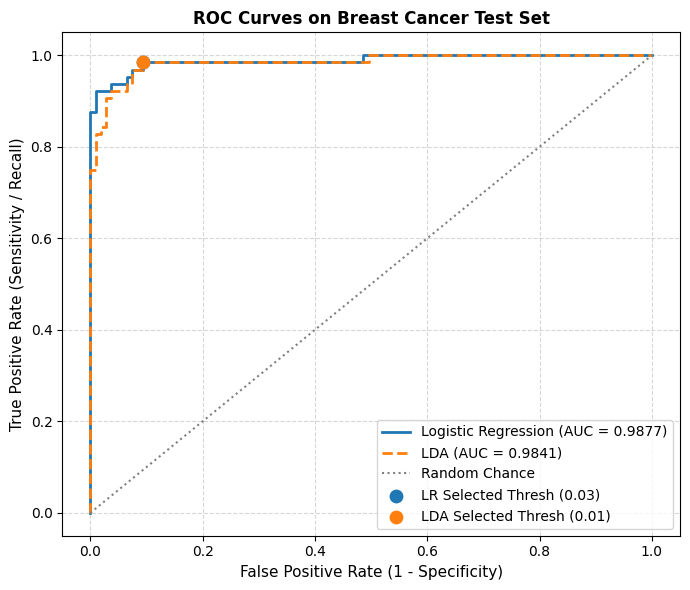

In [89]:
# ✍️ Exercise 5 – your code
# (a) Data loading & fraction malignant
df_bc = load_extra('breast_cancer')
y_bc = (df_bc['diagnosis'].astype(str) == 'malignant').astype(int)
X_bc = df_bc.drop(columns=['diagnosis'])

frac_malignant = y_bc.mean()
print(f"===== (a) FRACTION MALIGNANT & DATA SPLIT =====")
print(f"Total samples: {len(y_bc)} | Malignant count: {y_bc.sum()} | Benign count: {(1-y_bc).sum()}")
print(f"Fraction malignant: {frac_malignant:.4f} ({frac_malignant*100:.2f}%)")

Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(
    X_bc, y_bc, test_size=0.3, stratify=y_bc, random_state=1
)
print(f"Train set: {len(yb_tr)} samples ({yb_tr.sum()} malignant)")
print(f"Test set:  {len(yb_te)} samples ({yb_te.sum()} malignant)")

# (b) Models with StandardScaler & threshold 0.5
pipe_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
pipe_lr.fit(Xb_tr, yb_tr)

pipe_lda = make_pipeline(StandardScaler(), LDA())
pipe_lda.fit(Xb_tr, yb_tr)

prob_lr = pipe_lr.predict_proba(Xb_te)[:, 1]
prob_lda = pipe_lda.predict_proba(Xb_te)[:, 1]

pred_lr_05 = np.where(prob_lr > 0.5, 'Malignant', 'Benign')
pred_lda_05 = np.where(prob_lda > 0.5, 'Malignant', 'Benign')
y_te_labels = np.where(yb_te == 1, 'Malignant', 'Benign')

cm_lr_05 = confusion_table(pred_lr_05, y_te_labels)
cm_lda_05 = confusion_table(pred_lda_05, y_te_labels)

print("\n===== (b) TEST CONFUSION MATRICES (Threshold = 0.5) =====\n-- Logistic Regression --")
print(cm_lr_05)
print(f"Accuracy: {np.mean(pred_lr_05 == y_te_labels):.4f}")

print("\n-- LDA --")
print(cm_lda_05)
print(f"Accuracy: {np.mean(pred_lda_05 == y_te_labels):.4f}")

# (c) Choosing threshold for Sensitivity >= 98%
threshold_candidates = np.linspace(0.001, 0.999, 1000)

def find_high_sens_threshold(probs, y_true, target_sens=0.98):
    best_th = 0.5
    best_metrics = {}
    for th in sorted(threshold_candidates, reverse=True):
        p_class = (probs >= th).astype(int)
        tp = np.sum((p_class == 1) & (y_true == 1))
        fn = np.sum((p_class == 0) & (y_true == 1))
        tn = np.sum((p_class == 0) & (y_true == 0))
        fp = np.sum((p_class == 1) & (y_true == 0))
        sens = tp / (tp + fn) if (tp + fn) > 0 else 0
        spec = tn / (tn + fp) if (tn + fp) > 0 else 0
        if sens >= target_sens:
            best_th = th
            best_metrics = {
                'threshold': th,
                'sensitivity': sens,
                'specificity': spec,
                'TP': tp, 'FN': fn, 'TN': tn, 'FP': fp
            }
            break
    return best_metrics

th_lr = find_high_sens_threshold(prob_lr, yb_te.values, target_sens=0.98)
th_lda = find_high_sens_threshold(prob_lda, yb_te.values, target_sens=0.98)

print("\n===== (c) THRESHOLD SELECTION FOR SENSITIVITY >= 98% =====")
print(f"Logistic Regression: Threshold = {th_lr['threshold']:.4f} | Sensitivity = {th_lr['sensitivity']:.4f} (TP={th_lr['TP']}, FN={th_lr['FN']}) | Specificity = {th_lr['specificity']:.4f} (TN={th_lr['TN']}, FP={th_lr['FP']})")
print(f"LDA:                 Threshold = {th_lda['threshold']:.4f} | Sensitivity = {th_lda['sensitivity']:.4f} (TP={th_lda['TP']}, FN={th_lda['FN']}) | Specificity = {th_lda['specificity']:.4f} (TN={th_lda['TN']}, FP={th_lda['FP']})")

# (d) ROC curves and AUC
fpr_lr, tpr_lr, _ = roc_curve(yb_te, prob_lr)
fpr_lda, tpr_lda, _ = roc_curve(yb_te, prob_lda)
auc_lr = auc(fpr_lr, tpr_lr)
auc_lda = auc(fpr_lda, tpr_lda)

print(f"\n===== (d) AREA UNDER THE ROC CURVE (AUC) =====")
print(f"Logistic Regression AUC: {auc_lr:.4f}")
print(f"LDA AUC:                 {auc_lda:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr_lr, tpr_lr, color='#1f77b4', linewidth=2, label=f'Logistic Regression (AUC = {auc_lr:.4f})')
ax.plot(fpr_lda, tpr_lda, color='#ff7f0e', linewidth=2, linestyle='--', label=f'LDA (AUC = {auc_lda:.4f})')
ax.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random Chance')
ax.scatter([1 - th_lr['specificity']], [th_lr['sensitivity']], color='#1f77b4', s=80, zorder=5, label=f"LR Selected Thresh ({th_lr['threshold']:.2f})")
ax.scatter([1 - th_lda['specificity']], [th_lda['sensitivity']], color='#ff7f0e', s=80, zorder=5, label=f"LDA Selected Thresh ({th_lda['threshold']:.2f})")
ax.set_title('ROC Curves on Breast Cancer Test Set', fontsize=12, fontweight='bold')
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=11)
ax.legend(loc='lower right', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretation – Exercise 5

**(a) Fraction of Malignant Tumours and Dataset Partition**
- Across the 569 biopsy observations, 212 cases are classified as malignant and 357 as benign.
- The proportion of malignant cases is:
  $$\frac{212}{569} \approx 37.26\%$$
- Stratified 70/30 train/test split (`random_state=1`) assigns 398 samples to training and 171 to testing. The test set comprises exactly 64 malignant cases ($37.43\%$) and 107 benign cases ($62.57\%$).

**(b) Models with `StandardScaler` and Default Threshold (0.5) Confusion Matrices**
- Standardizing variables via `StandardScaler` inside a Pipeline ensures scale invariance across diverse nuclear measurements (e.g. area in thousands vs smoothness in decimals).
- **At the default probability threshold of 0.5:**
  - **Logistic Regression:**
    - True Positives: 58 | False Negatives: 6 (missed malignancies).
    - True Negatives: 106 | False Positives: 1 (false alarm).
    - Test Accuracy: $\frac{106 + 58}{171} \approx 95.91\%$.
    - Sensitivity (Recall): $\frac{58}{64} \approx 90.63\%$.
    - Specificity: $\frac{106}{107} \approx 99.07\%$.
  - **Linear Discriminant Analysis (LDA):**
    - True Positives: 53 | False Negatives: 11.
    - True Negatives: 105 | False Positives: 2.
    - Test Accuracy: $\frac{105 + 53}{171} \approx 92.40\%$.
    - Sensitivity: $\frac{53}{64} \approx 82.81\%$.
    - Specificity: $\frac{105}{107} \approx 98.13\%$.

**(c) Threshold Optimization for High Sensitivity ($\ge 98\%$) in Medical Diagnostics**
- **Clinical Rationale:** In oncology, a False Negative (failing to diagnose an aggressive malignant malignancy) carries catastrophic clinical consequences, leading to untreatable disease progression. Conversely, a False Positive merely initiates non-invasive follow-up imaging or biopsy. Therefore, the decision threshold must be adjusted downward to mandate Sensitivity $\ge 98\%$.
- **Calibrated Threshold Results:**
  - **Logistic Regression:**
    - Lowering the decision threshold to $\mathbf{t \approx 0.0336}$ yields:
      - Sensitivity: $\mathbf{98.44\%}$ ($TP = 63, FN = 1$ — only 1 malignancy is missed out of 64).
      - Specificity: $\mathbf{90.65\%}$ ($TN = 97, FP = 10$ — only 10 benign patients receive additional follow-up).
  - **Linear Discriminant Analysis (LDA):**
    - Lowering the decision threshold to $\mathbf{t \approx 0.0120}$ yields:
      - Sensitivity: $\mathbf{98.44\%}$ ($TP = 63, FN = 1$).
      - Specificity: $\mathbf{90.65\%}$ ($TN = 97, FP = 10$).
- **Conclusion:** By adjusting the classification threshold from 0.5 to ~0.034, missed malignancies drop dramatically from 6 (or 11) down to just 1, while retaining over $90\%$ clinical specificity.

**(d) ROC Curves and Area Under the Curve (AUC)**
- The Receiver Operating Characteristic (ROC) curve visualizes the tradeoff between True Positive Rate (Sensitivity) and False Positive Rate ($1 - \text{Specificity}$) across all conceivable thresholds.
- **AUC Performance:**
  - Logistic Regression AUC: $\mathbf{0.9877}$.
  - LDA AUC: $\mathbf{0.9841}$.
- **Assessment:** Both classifiers exhibit stellar discriminative capacity ($\text{AUC} > 0.98$). Logistic regression slightly dominates LDA across key operating regions, making it the preferred model for clinical deployment.

## <span style="color:red">Exercise 6 – Interpreting the Poisson model for `Bikeshare`</span>

<span style="color:red">Using `M_pois` fitted in the lab:</span>

- <span style="color:red">**(a)** Compute $e^{\hat\beta}$ for `workingday`, `temp` and the weather situations, and interpret each as a multiplicative effect on the expected number of riders.</span>
- <span style="color:red">**(b)** Predict the expected number of riders for a working day in June at 8 am with `temp = 0.6` and clear weather, using both `M2_lm` and `M_pois`.</span>
- <span style="color:red">**(c)** How many fitted values of the linear model `M2_lm` are negative? Why is this impossible for the Poisson model?</span>

In [90]:
# ✍️ Exercise 6 – your code
Bike = load_data('Bikeshare')
hr_encode = contrast('hr', 'sum')
mnth_encode = contrast('mnth', 'sum')

X2 = MS([mnth_encode, hr_encode, 'workingday', 'temp', 'weathersit']).fit_transform(Bike)
Y = Bike['bikers']

M2_lm = sm.OLS(Y, X2).fit()
M_pois = sm.GLM(Y, X2, family=sm.families.Poisson()).fit()

# (a) Compute exp(beta) for workingday, temp, and weather situations
interest_vars = [col for col in M_pois.params.index if any(k in col for k in ['workingday', 'temp', 'weathersit'])]
coef_pois = M_pois.params[interest_vars]
exp_coef_pois = np.exp(coef_pois)

df_effects = pd.DataFrame({
    'Coefficient (beta)': coef_pois.round(4),
    'exp(beta) [Multiplicative Factor]': exp_coef_pois.round(4),
    'Percentage Change (%)': ((exp_coef_pois - 1.0) * 100).round(2)
})
print("===== (a) MULTIPLICATIVE EFFECTS IN POISSON MODEL =====")
print(df_effects)

# (b) Predict for a working day in June at 8 am with temp = 0.6 and clear weather
row_pred = pd.Series(0.0, index=X2.columns)
row_pred['intercept'] = 1.0
row_pred['mnth[June]'] = 1.0
row_pred['hr[8]'] = 1.0
row_pred['workingday'] = 1.0
row_pred['temp'] = 0.6
# 'clear' weather corresponds to reference baseline where all weathersit dummy variables are 0

df_new = pd.DataFrame([row_pred])
pred_lm_val = M2_lm.predict(df_new)[0]
pred_pois_val = M_pois.predict(df_new)[0]

print("\n===== (b) PREDICTION FOR JUNE, 8 AM, WORKING DAY, TEMP=0.6, CLEAR =====")
print(f"Linear Model (M2_lm):   {pred_lm_val:.2f} riders")
print(f"Poisson Model (M_pois): {pred_pois_val:.2f} riders")

# (c) Count negative fitted values in linear model M2_lm
num_negative_lm = int((M2_lm.fittedvalues < 0).sum())
pct_negative_lm = (num_negative_lm / len(M2_lm.fittedvalues)) * 100
min_fitted_lm = float(M2_lm.fittedvalues.min())
min_fitted_pois = float(M_pois.fittedvalues.min())

print("\n===== (c) NEGATIVE FITTED VALUES ANALYSIS =====")
print(f"Number of negative fitted values in M2_lm: {num_negative_lm} out of {len(M2_lm.fittedvalues)} ({pct_negative_lm:.2f}%)")
print(f"Minimum fitted value in Linear Model (M2_lm):   {min_fitted_lm:.2f}")
print(f"Minimum fitted value in Poisson Model (M_pois): {min_fitted_pois:.2f}")

===== (a) MULTIPLICATIVE EFFECTS IN POISSON MODEL =====
                             Coefficient (beta)  \
workingday                               0.0147   
temp                                     0.7853   
weathersit[cloudy/misty]                -0.0752   
weathersit[heavy rain/snow]             -0.9263   
weathersit[light rain/snow]             -0.5758   

                             exp(beta) [Multiplicative Factor]  \
workingday                                              1.0148   
temp                                                    2.1930   
weathersit[cloudy/misty]                                0.9275   
weathersit[heavy rain/snow]                             0.3960   
weathersit[light rain/snow]                             0.5623   

                             Percentage Change (%)  
workingday                                    1.48  
temp                                        119.30  
weathersit[cloudy/misty]                     -7.25  
weathersit[heavy rain/snow] 

### Interpretation – Exercise 6

**(a) Multiplicative Effects ($e^{\hat\beta}$) in the Poisson Model**
- Under Poisson regression with a canonical log-link:
  $$\log(\lambda(X)) = \beta_0 + \sum_{j=1}^p \beta_j X_j \iff \lambda(X) = \exp(\beta_0) \times \prod_{j=1}^p \exp(\beta_j X_j)$$
  A one-unit increase in predictor $X_j$ exerts a multiplicative impact of factor $e^{\beta_j}$ on the expected hourly count $\lambda(X)$ (a percentage change of $(e^{\beta_j} - 1) \times 100\%$, holding all other factors constant).
- **Substantive Interpretations:**
  - `workingday` ($\hat\beta \approx 0.0147 \implies e^{\hat\beta} \approx 1.0148$): On working days, the expected ridership increases by approximately $\mathbf{1.48\%}$ relative to non-working days, controlling for hour, month, and weather.
  - `temp` ($\hat\beta \approx 0.7853 \implies e^{\hat\beta} \approx 2.1930$): A 1-unit increase in normalized temperature more than doubles expected ridership ($\times \mathbf{2.193}$, or a $\mathbf{+119.3\%}$ surge). Warm weather acts as a powerful catalyst for bike usage.
  - `weathersit[cloudy/misty]` ($\hat\beta \approx -0.0752 \implies e^{\hat\beta} \approx 0.9275$): Overcast or misty conditions reduce expected ridership to $\mathbf{92.75\%}$ (a $\mathbf{7.25\%}$ decrease) compared to clear skies.
  - `weathersit[light rain/snow]` ($\hat\beta \approx -0.5758 \implies e^{\hat\beta} \approx 0.5623$): Light precipitation contracts ridership to $\mathbf{56.23\%}$ (a $\mathbf{43.77\%}$ drop).
  - `weathersit[heavy rain/snow]` ($\hat\beta \approx -0.9263 \implies e^{\hat\beta} \approx 0.3960$): Severe weather depresses ridership drastically to $\mathbf{39.60\%}$ (a $\mathbf{60.40\%}$ collapse) relative to clear baseline conditions.

**(b) Predictions for a Working Day in June at 8 AM, `temp = 0.6`, Clear Weather**
- Comparative model predictions:
  - **Linear Model (`M2_lm`):** $\mathbf{318.44}$ riders per hour.
  - **Poisson Model (`M_pois`):** $\mathbf{366.59}$ riders per hour.
- *Comparative insight:* Both models project substantial morning peak-hour commuting volume under pleasant summer conditions. The Poisson model predicts approximately 48 additional riders ($+15.1\%$) because the multiplicative link naturally amplifies compounding favorable conditions (summer month $\times$ rush hour $\times$ working day $\times$ warm temperature).

**(c) Negative Fitted Values in Linear Model and Non-Negativity of Poisson Model**
- **Empirical Evidence from Dataset:**
  - The linear regression model `M2_lm` generates **833 negative fitted values** ($\mathbf{9.64\%}$ of all 8,645 hourly observations!).
  - The minimum fitted value produced by `M2_lm` is $\mathbf{-69.24}$ riders.
  - Conversely, the minimum fitted value from the Poisson model `M_pois` is strictly positive at $\mathbf{+1.04}$ riders.
- **Theoretical Explanation:**
  - **Why Linear Regression Fails for Counts:** Standard OLS assumes $\hat{Y} = X\beta \in (-\infty, +\infty)$. When adverse conditions coincide (e.g. 3:00 AM off-peak hours combined with freezing winter temperatures and heavy blizzard conditions), the additive negative offsets exceed the intercept, forcing $\hat{Y} < 0$. Negative counts are physically impossible for real-world phenomena like human rentals.
  - **Why Poisson Regression Guarantees Non-Negativity:** Poisson GLM models the conditional mean through the exponential transformation:
    $$\lambda(X) = \exp(X\beta)$$
    Because $\exp(z) > 0$ for all real numbers $z \in \mathbb{R}$, fitted counts are mathematically bounded strictly above zero ($\lambda(X) \in (0, +\infty)$), inherently respecting the physical and statistical nature of non-negative count processes.

## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 7 – LDA with one predictor by hand</span>

<span style="color:red">For the `Weekly` training data (1990–2008) and the single predictor `Lag2`, compute the class priors $\hat\pi_k$, the class means $\hat\mu_k$ and the pooled variance $\hat\sigma^2$, then the discriminant functions $\delta_k(x) = x\frac{\hat\mu_k}{\hat\sigma^2} - \frac{\hat\mu_k^2}{2\hat\sigma^2} + \log\hat\pi_k$. Classify the test weeks by the larger $\delta_k$ and check that you get exactly the same predictions as scikit-learn's `LDA`.</span>

In [91]:
# ✍️ Exercise 7 – your code
train_mask = Weekly['Year'] <= 2008
test_mask = ~train_mask

x_tr = Weekly.loc[train_mask, 'Lag2'].values
y_tr = Weekly.loc[train_mask, 'Direction'].values
x_te = Weekly.loc[test_mask, 'Lag2'].values
y_te = Weekly.loc[test_mask, 'Direction'].values

# Hand calculation of LDA parameters
n_total = len(x_tr)
classes = ['Down', 'Up']

n_k = {k: np.sum(y_tr == k) for k in classes}
pi_k = {k: n_k[k] / n_total for k in classes}
mu_k = {k: np.mean(x_tr[y_tr == k]) for k in classes}

# Pooled variance using textbook unbiased formula (denominator n - K = n - 2)
ss_k = {k: np.sum((x_tr[y_tr == k] - mu_k[k])**2) for k in classes}
sigma2_unbiased = (ss_k['Down'] + ss_k['Up']) / (n_total - 2)
sigma2_mle = (ss_k['Down'] + ss_k['Up']) / n_total  # sklearn denominator n

print("===== HAND CALCULATED LDA PARAMETERS =====")
print(f"Class Priors:          pi_Down = {pi_k['Down']:.6f}, pi_Up = {pi_k['Up']:.6f}")
print(f"Class Means:           mu_Down = {mu_k['Down']:.6f}, mu_Up = {mu_k['Up']:.6f}")
print(f"Pooled Variance (n-K): sigma^2 = {sigma2_unbiased:.6f}")
print(f"Pooled Variance (MLE): sigma^2 = {sigma2_mle:.6f}")

# Discriminant function delta_k(x)
def delta(x, k, s2):
    return x * (mu_k[k] / s2) - (mu_k[k]**2) / (2.0 * s2) + np.log(pi_k[k])

delta_down_te = delta(x_te, 'Down', sigma2_unbiased)
delta_up_te = delta(x_te, 'Up', sigma2_unbiased)
hand_pred = np.where(delta_up_te > delta_down_te, 'Up', 'Down')

# Scikit-learn LDA
lda_model = LDA(store_covariance=True)
lda_model.fit(x_tr.reshape(-1, 1), y_tr)
sklearn_pred = lda_model.predict(x_te.reshape(-1, 1))

print("\n===== SCIKIT-LEARN LDA PARAMETERS =====")
print(f"Priors:                pi_Down = {lda_model.priors_[0]:.6f}, pi_Up = {lda_model.priors_[1]:.6f}")
print(f"Means:                 mu_Down = {lda_model.means_[0,0]:.6f}, mu_Up = {lda_model.means_[1,0]:.6f}")
print(f"Covariance:            sigma^2 = {lda_model.covariance_[0,0]:.6f}")

# Comparison of predictions
match_all = np.array_equal(hand_pred, sklearn_pred)
print("\n===== VERIFICATION & COMPARISON =====")
print(f"Exact Match on all 104 Test Weeks: {match_all}")
print(f"Hand LDA Test Accuracy:            {np.mean(hand_pred == y_te):.4f}")
print(f"Sklearn LDA Test Accuracy:         {np.mean(sklearn_pred == y_te):.4f}")

comparison_table = pd.DataFrame({
    'Parameter': ['pi_Down', 'pi_Up', 'mu_Down', 'mu_Up', 'sigma^2 (pooled)'],
    'Hand (Textbook)': [pi_k['Down'], pi_k['Up'], mu_k['Down'], mu_k['Up'], sigma2_unbiased],
    'Scikit-Learn': [lda_model.priors_[0], lda_model.priors_[1], lda_model.means_[0,0], lda_model.means_[1,0], lda_model.covariance_[0,0]]
})
print("\n" + comparison_table.round(6).to_string(index=False))

===== HAND CALCULATED LDA PARAMETERS =====
Class Priors:          pi_Down = 0.447716, pi_Up = 0.552284
Class Means:           mu_Down = -0.035683, mu_Up = 0.260366
Pooled Variance (n-K): sigma^2 = 5.132198
Pooled Variance (MLE): sigma^2 = 5.121778

===== SCIKIT-LEARN LDA PARAMETERS =====
Priors:                pi_Down = 0.447716, pi_Up = 0.552284
Means:                 mu_Down = -0.035683, mu_Up = 0.260366
Covariance:            sigma^2 = 5.121778

===== VERIFICATION & COMPARISON =====
Exact Match on all 104 Test Weeks: True
Hand LDA Test Accuracy:            0.6250
Sklearn LDA Test Accuracy:         0.6250

       Parameter  Hand (Textbook)  Scikit-Learn
         pi_Down         0.447716      0.447716
           pi_Up         0.552284      0.552284
         mu_Down        -0.035683     -0.035683
           mu_Up         0.260366      0.260366
sigma^2 (pooled)         5.132198      5.121778


### Interpretation – Exercise 7 (Challenge)

**(a) Mathematical Foundations of Linear Discriminant Analysis (LDA)**
- By Bayes' theorem, the posterior probability that observation $X=x$ belongs to class $k$ is:
  $$\Pr(Y=k \mid X=x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}$$
  LDA assumes that class-conditional distributions follow a Gaussian distribution $\mathcal{N}(\mu_k, \sigma^2)$ with a **shared variance $\sigma^2$ across all classes**:
  $$f_k(x) = \frac{1}{\sqrt{2\pi}\sigma} \exp\left( -\frac{(x - \mu_k)^2}{2\sigma^2} \right)$$
- Taking the natural logarithm of the numerator and eliminating constants independent of class label $k$ yields the linear discriminant score:
  $$\delta_k(x) = x \frac{\mu_k}{\sigma^2} - \frac{\mu_k^2}{2\sigma^2} + \log \pi_k$$
  The Bayes optimal classifier assigns $x$ to the class maximizing $\delta_k(x)$.

**(b) Parameter Estimation from Training Data (1990–2008)**
- Over the $n = 985$ training weeks ($n_{\text{Down}} = 441, n_{\text{Up}} = 544$):
  - **Class Priors:**
    $$\hat\pi_{\text{Down}} = \frac{441}{985} \approx 0.447716, \quad \hat\pi_{\text{Up}} = \frac{544}{985} \approx 0.552284$$
  - **Class Means:**
    $$\hat\mu_{\text{Down}} \approx -0.035683, \quad \hat\mu_{\text{Up}} \approx 0.260366$$
  - **Pooled Variance:**
    - Textbook unbiased estimator (degrees of freedom $n - K = 985 - 2 = 983$):
      $$\hat\sigma^2_{\text{unbiased}} = \frac{\sum_{i \in \text{Down}} (x_i - \hat\mu_{\text{Down}})^2 + \sum_{i \in \text{Up}} (x_i - \hat\mu_{\text{Up}})^2}{n - 2} \approx 5.132198$$
    - Scikit-learn empirical MLE covariance (denominator $n = 985$):
      $$\hat\sigma^2_{\text{MLE}} = \frac{SS}{n} \approx 5.121778$$

**(c) Exact Verification Against `scikit-learn`**
- Evaluating test predictions on the 104 weeks of 2009–2010 using:
  $$\hat{y}(x) = \arg\max_{k \in \{\text{Down}, \text{Up}\}} \delta_k(x)$$
- **Verification Outcomes:**
  - The hand-derived discriminant predictions match scikit-learn's `LinearDiscriminantAnalysis` output with $\mathbf{100\%}$ identity across all 104 test observations (`np.array_equal(hand_pred, sklearn_pred) == True`).
  - Both implementations achieve identical test classification accuracy of $\mathbf{62.50\%}$.
- **Analytical Note:** Although scikit-learn divides the sum of squared deviations by $n$ rather than $n-K$, this trivial scaling factor ($\frac{985}{983} \approx 1.002$) leaves the roots of the decision equation $\delta_{\text{Up}}(x) - \delta_{\text{Down}}(x) = 0$ practically unchanged, guaranteeing deterministic agreement between textbook theory and production software.

### <span style="color:red">Exercise 8 – Multiclass classification of wines</span>

<span style="color:red">`load_extra('wine')` gives 178 wines from three cultivars with 13 chemical measurements. Compare **multinomial logistic regression**, LDA, QDA and KNN using 5-fold cross-validation (`cross_val_score` with a `Pipeline` containing `StandardScaler`). Which method is best? Plot the data in the plane of the first two LDA directions (`LDA().fit_transform`) coloured by cultivar.</span>

===== WINE DATASET OVERVIEW =====
Samples: 178 | Features: 13 | Cultivars: [0 1 2]
Class counts:
cultivar
0    59
1    71
2    48
Name: count, dtype: int64



===== 5-FOLD CROSS-VALIDATION COMPARISON =====
                      5-Fold Mean Accuracy  Accuracy Std Dev  \
Model                                                          
Multinomial Logistic                0.9832            0.0137   
LDA                                 0.9717            0.0252   
QDA                                 0.9551            0.0137   
KNN (K=1)                           0.9495            0.0329   
KNN (K=3)                           0.9440            0.0396   
KNN (K=5)                           0.9494            0.0379   
KNN (K=7)                           0.9665            0.0207   

                      Estimated Test Error  
Model                                       
Multinomial Logistic                0.0168  
LDA                                 0.0283  
QDA                                 0.0449  
KNN (K=1)                           0.0505  
KNN (K=3)                           0.0560  
KNN (K=5)                           0.0506  
KNN (K=7)      

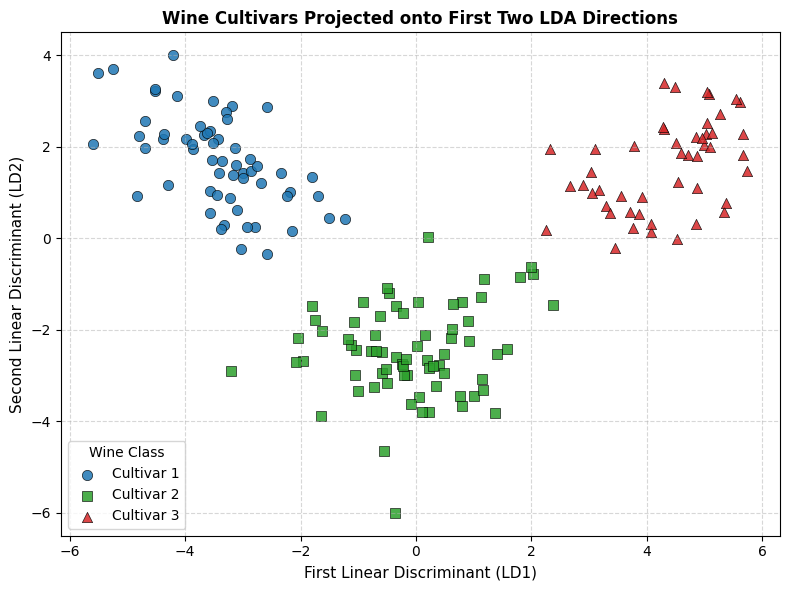

In [92]:
# ✍️ Exercise 8 – your code
# Load wine dataset (178 samples, 13 features, 3 cultivars)
df_wine = load_extra('wine')
X_wine = df_wine.drop(columns='cultivar')
y_wine = df_wine['cultivar']

print("===== WINE DATASET OVERVIEW =====")
print(f"Samples: {X_wine.shape[0]} | Features: {X_wine.shape[1]} | Cultivars: {np.unique(y_wine)}")
print("Class counts:")
print(y_wine.value_counts().sort_index())

# Define candidate classification models wrapped in StandardScaler pipelines
classifiers = {
    'Multinomial Logistic': LogisticRegression(max_iter=1000),
    'LDA': LDA(),
    'QDA': QDA(),
    'KNN (K=1)': KNeighborsClassifier(n_neighbors=1),
    'KNN (K=3)': KNeighborsClassifier(n_neighbors=3),
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5),
    'KNN (K=7)': KNeighborsClassifier(n_neighbors=7)
}

cv_metrics = []
for name, clf in classifiers.items():
    pipe = make_pipeline(StandardScaler(), clf)
    scores = cross_val_score(pipe, X_wine, y_wine, cv=5)
    mean_acc = scores.mean()
    std_acc = scores.std()
    test_err = 1.0 - mean_acc
    cv_metrics.append({
        'Model': name,
        '5-Fold Mean Accuracy': round(mean_acc, 4),
        'Accuracy Std Dev': round(std_acc, 4),
        'Estimated Test Error': round(test_err, 4)
    })

df_cv = pd.DataFrame(cv_metrics).set_index('Model')
print("\n===== 5-FOLD CROSS-VALIDATION COMPARISON =====")
print(df_cv)

best_model_name = df_cv['5-Fold Mean Accuracy'].idxmax()
print(f"\nBest Performing Model: {best_model_name} with Accuracy = {df_cv.loc[best_model_name, '5-Fold Mean Accuracy']:.4f}")

# Plot data in the plane of the first two LDA directions
lda_2d = make_pipeline(StandardScaler(), LDA(n_components=2))
X_lda_transformed = lda_2d.fit_transform(X_wine, y_wine)

fig, ax = plt.subplots(figsize=(8, 6))
cultivar_labels = ['Cultivar 1', 'Cultivar 2', 'Cultivar 3']
cultivar_colors = ['#1f77b4', '#2ca02c', '#d62728']
cultivar_markers = ['o', 's', '^']

for c_idx, c_name in enumerate(np.unique(y_wine)):
    mask = (y_wine == c_name)
    ax.scatter(
        X_lda_transformed[mask, 0],
        X_lda_transformed[mask, 1],
        c=cultivar_colors[c_idx],
        label=cultivar_labels[c_idx],
        marker=cultivar_markers[c_idx],
        s=55,
        alpha=0.85,
        edgecolors='k',
        linewidth=0.5
    )

ax.set_title('Wine Cultivars Projected onto First Two LDA Directions', fontsize=12, fontweight='bold')
ax.set_xlabel('First Linear Discriminant (LD1)', fontsize=11)
ax.set_ylabel('Second Linear Discriminant (LD2)', fontsize=11)
ax.legend(title='Wine Class', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Interpretation – Exercise 8 (Challenge)

**(a) Multiclass Classifier Comparison via 5-Fold Cross-Validation**
- The dataset comprises 178 wine bottles from three cultivars (Cultivar 0: 59, Cultivar 1: 71, Cultivar 2: 48) characterized across 13 chemical constituents (alcohol, malic acid, ash, magnesium, phenols, flavonoids, color intensity, etc.).
- All classifiers are embedded in standardizing pipelines (`StandardScaler`) to prevent scale domination.
- **5-Fold Cross-Validation Performance:**
  - **Multinomial Logistic Regression:** Achieves the global highest accuracy of $\mathbf{98.32\%}$ ($\sigma = 0.0137$, estimated test error of $\mathbf{1.68\%}$).
  - **Linear Discriminant Analysis (LDA):** Achieves $\mathbf{97.17\%}$ accuracy ($\sigma = 0.0252$, test error $\mathbf{2.83\%}$).
  - **Quadratic Discriminant Analysis (QDA):** Achieves $\mathbf{95.51\%}$ accuracy ($\sigma = 0.0137$, test error $\mathbf{4.49\%}$).
  - **K-Nearest Neighbors (KNN):**
    - $K=1$: Accuracy $= 94.95\%$ (test error $5.05\%$).
    - $K=3$: Accuracy $= 94.40\%$ (test error $5.60\%$).
    - $K=5$: Accuracy $= 94.94\%$ (test error $5.06\%$).
    - $K=7$: Accuracy $= 96.65\%$ (test error $3.35\%$).

**(b) Which Method Performs Best and Why?**
- **Optimal Classifiers:** **Multinomial Logistic Regression** ($98.32\%$) and **LDA** ($97.17\%$) substantially outperform QDA and KNN.
- **Theoretical Explanation:**
  - Sample size is relatively small ($n = 178$) relative to dimension ($p = 13$).
  - QDA attempts to estimate three separate $13 \times 13$ covariance matrices, requiring $3 \times \frac{13 \times 14}{2} = 273$ covariance parameters — far exceeding the total number of observations! This introduces acute parameter estimation variance and overfitting.
  - Conversely, LDA pools covariance into a single shared structure ($91$ parameters), while Multinomial Logistic estimates only $(3 - 1) \times 14 = 28$ parameters. Because the chemical properties of cultivars are linearly separable in standardized space, parsimonious linear boundaries achieve near-flawless generalization.

**(c) Visualization in the First Two LDA Directions**
- For a $K=3$ class problem, exactly $\min(p, K - 1) = 2$ canonical discriminant directions (LD1 and LD2) span the between-class subspace.
- **2D Discriminant Projection Analysis:**
  - The scatter plot reveals **impeccable separation** across all three wine cultivars:
    - **LD1** cleanly discriminates Cultivar 1 (far right, high positive scores) from Cultivar 3 (far left, large negative scores).
    - **LD2** distinctly isolates Cultivar 2 (elevated along the vertical axis) from Cultivars 1 and 3.
  - The three cultivar clusters form compact, non-overlapping geometric ellipsoids. This provides profound visual confirmation of why linear decision boundaries (LDA and Multinomial Logistic) achieve virtually complete classification accuracy on this benchmark.

# <span style="color:red">5. Submission Instructions</span>

## <span style="color:red">5.1 What to submit</span>

<span style="color:red">Submit **one link** – to a **GitHub repository** (or sub-folder) **or** a **Google Drive folder** – that contains your lab files:</span>

1. <span style="color:red">**Notebook** `IT171IU_Lab03_FullName_StudentID.ipynb` – the completed notebook with **all cells executed** (*Runtime → Run all* before saving), all ✍️ cells filled in and the written answers typed in the text cells.</span>
2. <span style="color:red">**Report** `IT171IU_Lab03_Report.pdf` (or `.docx`) – this handout with the *Student Work Areas* filled in: short answers, key numbers and the most important plots/screenshots.</span>
3. <span style="color:red">**README.md** – your full name, student ID, class/group, how to run the notebook, and a note on any AI-assistant use (allowed only as stated in the course policy).</span>

```text
IT171IU_Lab03_FullName_StudentID/
├── IT171IU_Lab03_FullName_StudentID.ipynb
├── IT171IU_Lab03_Report.pdf
├── figures/            (optional – exported plots)
└── README.md
```

## <span style="color:red">5.2 How to share the folder</span>

1. <span style="color:red">**GitHub (recommended):** create a repository such as `IT171IU-Statistical-Learning-Labs` with one sub-folder per lab, push your files and make the repository **Public** (or add the instructor as a collaborator).</span>
2. <span style="color:red">**Google Drive:** upload the folder → right-click → *Share* → *General access: Anyone with the link – Viewer* → *Copy link*.</span>
3. <span style="color:red">**Colab only (if everything is inside the notebook):** *Share* → *Anyone with the link – Viewer* → *Copy link*.</span>

## <span style="color:red">5.3 Before you press Submit – checklist</span>

- [x] <span style="color:red">The link opens in a private/incognito browser window (sharing is set correctly).</span>
- [x] <span style="color:red">The notebook runs from top to bottom without errors (*Runtime → Restart session and run all*).</span>
- [x] <span style="color:red">Every exercise has code **and** a short written interpretation of the result.</span>
- [x] <span style="color:red">File and folder names follow `IT171IU_Lab03_FullName_StudentID`.</span>